# SEGMENTATION (23 August)

## Task 1: SIPAKMED (Multiclass Nucleus Segmentation + 5-Class Classification).

Using compute device: cuda
Identified 4049 matching image/nucleus-mask pairs across classes: ['dyskeratotic', 'koilocytotic', 'metaplastic', 'parabasal', 'superficial_intermediate']
Generating and resizing 2834 records for 'train' split...
Generating and resizing 607 records for 'val' split...
Generating and resizing 608 records for 'test' split...

Data preprocessing complete.

Starting joint training on SIPAKMED (5 classes)...
Epoch 01/50 | Train Loss: 1.9681 Acc: 0.615 Dice: 0.462 | Val Loss: 1.6934 Acc: 0.748 Dice: 0.451
Epoch 02/50 | Train Loss: 1.5579 Acc: 0.687 Dice: 0.556 | Val Loss: 1.5391 Acc: 0.722 Dice: 0.485
Epoch 03/50 | Train Loss: 1.4556 Acc: 0.705 Dice: 0.586 | Val Loss: 1.5302 Acc: 0.692 Dice: 0.502
Epoch 04/50 | Train Loss: 1.2965 Acc: 0.748 Dice: 0.618 | Val Loss: 1.0189 Acc: 0.842 Dice: 0.634
Epoch 05/50 | Train Loss: 1.2096 Acc: 0.764 Dice: 0.647 | Val Loss: 1.0291 Acc: 0.834 Dice: 0.614
Epoch 06/50 | Train Loss: 1.0744 Acc: 0.801 Dice: 0.684 | Val Loss: 0.9977 Ac

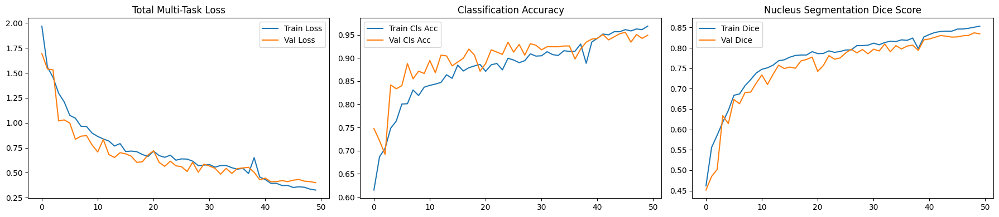


Final Test Classification Accuracy: 0.9490
Final Test Nucleus Segmentation Mean Dice Score: 0.8264

Classification Report:
                          precision    recall  f1-score   support

            dyskeratotic       0.95      0.98      0.97       122
            koilocytotic       0.94      0.87      0.90       124
             metaplastic       0.93      0.94      0.93       119
               parabasal       0.97      0.99      0.98       118
superficial_intermediate       0.95      0.96      0.96       125

                accuracy                           0.95       608
               macro avg       0.95      0.95      0.95       608
            weighted avg       0.95      0.95      0.95       608



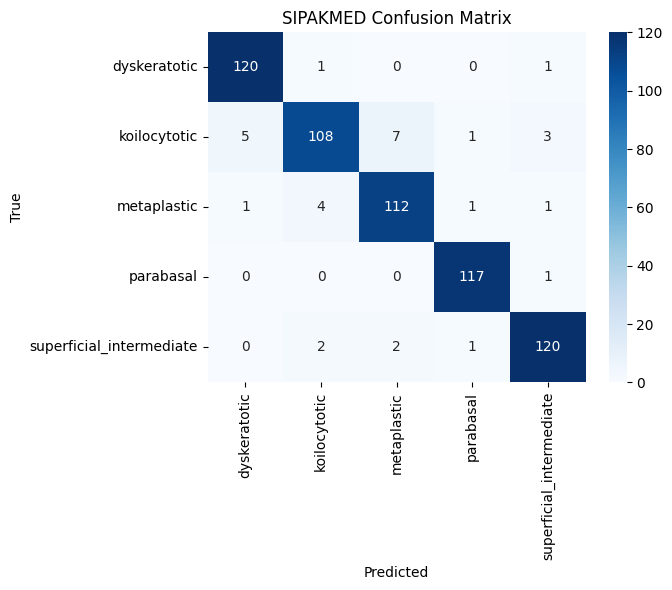

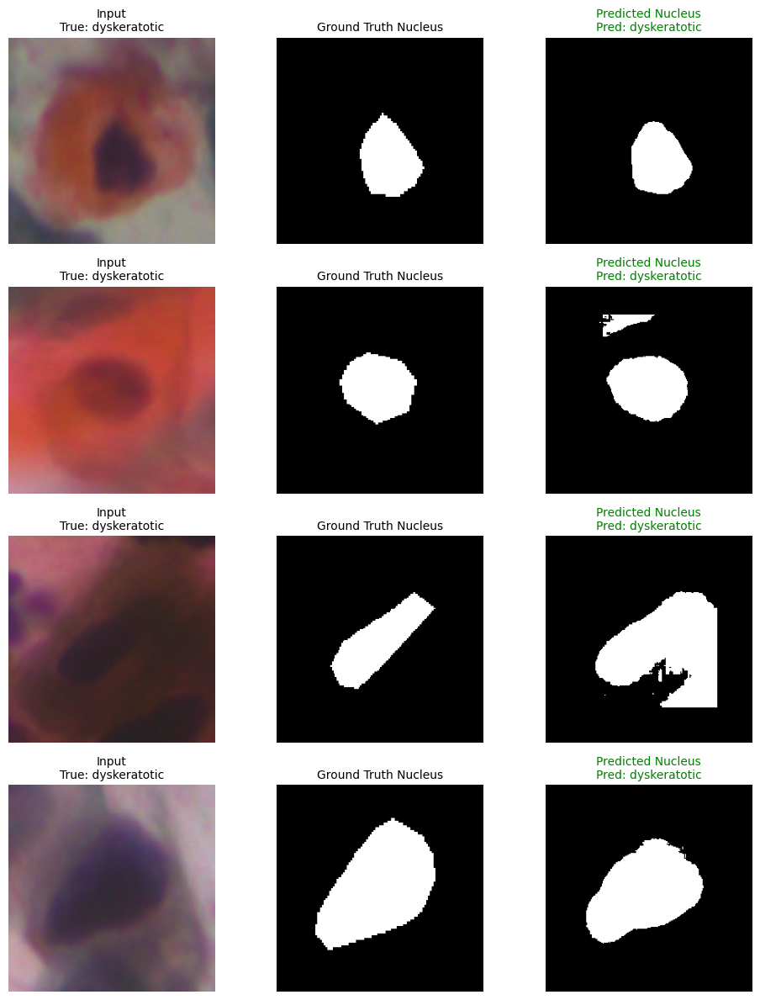

In [1]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Seed Configuration
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "sipakmed_multitask_data"
PLOTS_DIR = "plots_sipakmed"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. Coordinate File Parser & Mask Generator
# ---------------------------------------------------------
def load_dat_coordinates(dat_path):
    """Parses polygon coordinate vertices from SIPAKMED .dat files."""
    coords = []
    if not os.path.exists(dat_path):
        return None
    with open(dat_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.replace(",", " ").split()
            if len(parts) >= 2:
                try:
                    coords.append([float(parts[0]), float(parts[1])])
                except ValueError:
                    continue
    if len(coords) == 0:
        return None
    return np.array(coords, dtype=np.int32)


def canonicalize_sipakmed_class(folder_path: str) -> str:
    """Normalizes various SIPAKMED directory names into 5 canonical class labels."""
    name = folder_path.lower()
    if "dyskeratotic" in name:
        return "dyskeratotic"
    elif "koilocytotic" in name:
        return "koilocytotic"
    elif "metaplastic" in name:
        return "metaplastic"
    elif "parabasal" in name:
        return "parabasal"
    elif "superficial" in name or "intermediate" in name:
        return "superficial_intermediate"
    return None


# ---------------------------------------------------------
# 2. SIPAKMED Dataset Discovery & Generation
# ---------------------------------------------------------
SIPAKMED_RAW_DIR = "/kaggle/input/datasets/marinaeplissiti/sipakmed"

all_pairs = []

# Discover all .bmp images that have corresponding _nuc.dat files
for bmp_path in glob.glob(os.path.join(SIPAKMED_RAW_DIR, "**", "*.bmp"), recursive=True):
    base_name = os.path.splitext(bmp_path)[0]
    nuc_dat_path = f"{base_name}_nuc.dat"
    
    if os.path.exists(nuc_dat_path):
        cls_name = canonicalize_sipakmed_class(bmp_path)
        if cls_name is not None:
            all_pairs.append({
                "bmp_path": bmp_path,
                "nuc_dat": nuc_dat_path,
                "class_name": cls_name,
                "base_name": os.path.basename(base_name)
            })

if len(all_pairs) == 0:
    raise RuntimeError(f"No valid image/_nuc.dat pairs found in: {SIPAKMED_RAW_DIR}")

unique_classes = sorted(list(set(p["class_name"] for p in all_pairs)))
print(f"Identified {len(all_pairs)} matching image/nucleus-mask pairs across classes: {unique_classes}")

# Stratified 70% Train, 15% Val, 15% Test Split
pair_labels = [p["class_name"] for p in all_pairs]
train_pairs, temp_pairs = train_test_split(all_pairs, test_size=0.30, stratify=pair_labels, random_state=SEED)
temp_labels = [p["class_name"] for p in temp_pairs]
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_pairs, "val": val_pairs, "test": test_pairs}

for split_name, pairs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Generating and resizing {len(pairs)} records for '{split_name}' split...")
    for idx, pair in enumerate(pairs):
        img = cv2.imread(pair["bmp_path"], cv2.IMREAD_COLOR)
        if img is None:
            continue
        h, w = img.shape[:2]

        # Generate raster nucleus mask
        nuc_mask = np.zeros((h, w), dtype=np.uint8)
        nuc_pts = load_dat_coordinates(pair["nuc_dat"])
        if nuc_pts is not None and len(nuc_pts) > 0:
            cv2.drawContours(nuc_mask, [nuc_pts], -1, 255, -1)

        # Resize to model input dimension
        img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        mask_resized = cv2.resize(nuc_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        save_name = f"{pair['class_name']}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, save_name), img_resized)
        cv2.imwrite(os.path.join(masks_dir, save_name), mask_resized)

print("\nData preprocessing complete.")


# ---------------------------------------------------------
# 3. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class SipakmedMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=unique_classes):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        # Load RGB image
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        # Load binary mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = SipakmedMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = SipakmedMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = SipakmedMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 4. Joint Multi-Task Model (Res-UNet + Classifier)
# ---------------------------------------------------------

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
    )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)
        
        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)
        
        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Encoder features
        x1 = self.inc(x)         # 32, 224, 224
        x2 = self.down1(x1)      # 64, 112, 112
        x3 = self.down2(x2)      # 128, 56, 56
        x4 = self.down3(x3)      # 256, 28, 28
        
        feat = self.bottleneck_attn(x4)

        # Classification Head
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation Head
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))
        
        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))
        
        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))
        
        seg_logits = self.seg_out(d3)

        return seg_logits, cls_logits


# ---------------------------------------------------------
# 5. Combined Multi-Task Loss & Metrics
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(unique_classes)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 6. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on SIPAKMED ({len(unique_classes)} classes)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_sipakmed_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nLoaded optimal model weights from validation loss checkpoint.")


# ---------------------------------------------------------
# 7. Evaluation, Plots & Qualitative Predictions
# ---------------------------------------------------------
model.eval()

# 1. Training Curves Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/sipakmed_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=unique_classes, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=unique_classes, yticklabels=unique_classes)
plt.title("SIPAKMED Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/sipakmed_confusion_matrix.png", dpi=200)
plt.show()

# 4. Qualitative Test Predictions (Image | GT Mask | Pred Mask)
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = unique_classes[sample_labels[i].item()]
    p_cls = unique_classes[s_cls_preds[i]]

    # Original Image
    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    # Ground Truth Mask
    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Nucleus", fontsize=10)
    axes[i, 1].axis("off")

    # Predicted Mask
    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Predicted Nucleus\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/sipakmed_sample_inference.png", dpi=200)
plt.show()

## Task 2: Cytology dataset 1 (APCEM enhanced) multi-task pipeline 

Using compute device: cuda
Loaded 4134 images across classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Saving and generating nucleus masks for 'train' split (2893 images)...
Saving and generating nucleus masks for 'val' split (620 images)...
Saving and generating nucleus masks for 'test' split (621 images)...

Dataset preparation and nucleus mask extraction complete.

Starting joint training on Cytology Dataset 1 (Enhanced)...
Epoch 01/50 | Train Loss: 2.3789 Acc: 0.421 Dice: 0.266 | Val Loss: 2.3938 Acc: 0.411 Dice: 0.260
Epoch 02/50 | Train Loss: 2.0972 Acc: 0.479 Dice: 0.287 | Val Loss: 2.1835 Acc: 0.460 Dice: 0.303
Epoch 03/50 | Train Loss: 1.9941 Acc: 0.494 Dice: 0.300 | Val Loss: 1.9134 Acc: 0.561 Dice: 0.309
Epoch 04/50 | Train Loss: 1.9469 Acc: 0.521 Dice: 0.313 | Val Loss: 2.0219 Acc: 0.447 Dice: 0.327
Epoch 05/50 | Train Loss: 1.9303 Acc: 0.508 Dice: 0.323 | Val Loss: 2.1324 Acc: 0.395 Dice: 0.329
Epoch 06/50 | Train Loss: 1.8707 Acc: 0.527 Dice: 0.338 | Val Loss: 1.9320 Acc:

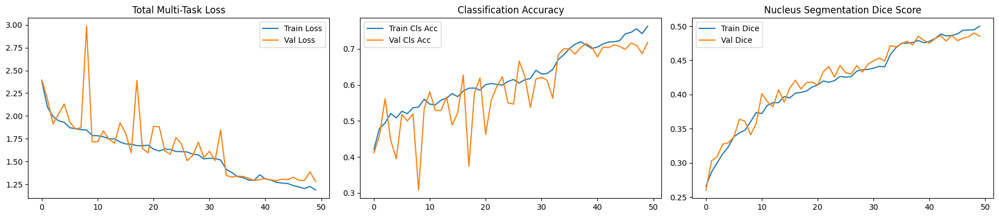


Final Test Classification Accuracy: 0.7246
Final Test Nucleus Segmentation Mean Dice Score: 0.4466

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.67      0.31      0.43        51
        HSIL       0.64      0.75      0.69       195
        LSIL       0.70      0.66      0.68       187
        NILM       0.96      0.94      0.95       117
         SCC       0.71      0.76      0.73        71

    accuracy                           0.72       621
   macro avg       0.73      0.69      0.70       621
weighted avg       0.73      0.72      0.72       621



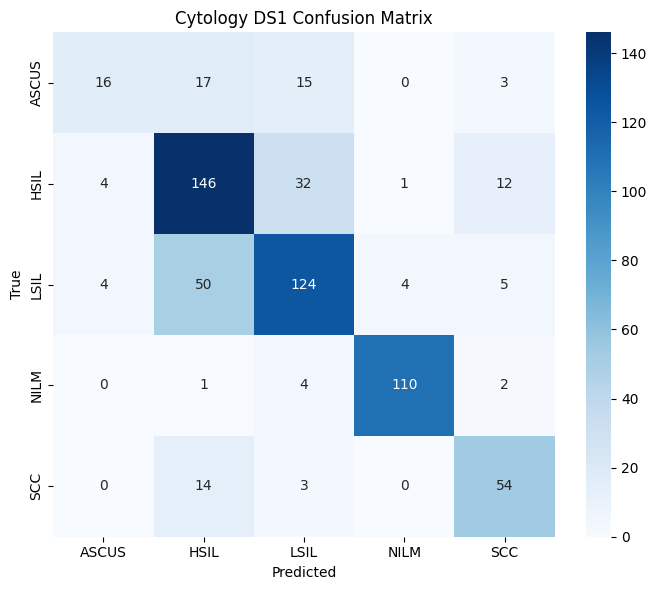

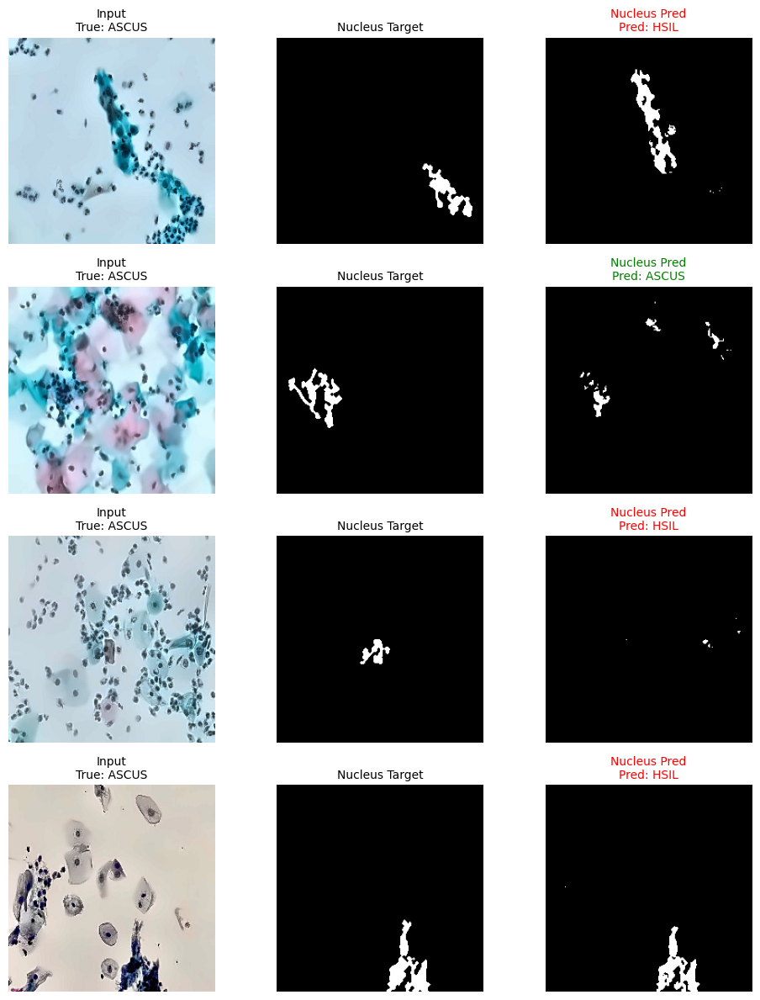

In [2]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_ds1_multitask_data"
PLOTS_DIR = "plots_cytology_ds1"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. Automated Cytology Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """
    Extracts high-contrast nucleus masks for cervical cytology cells
    using adaptive color-space thresholding (nuclei appear dark/chromatin-dense)
    followed by morphological refinement.
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # Adaptive thresholding to segment dark nuclear regions
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )
    
    # Morphological opening and closing to isolate the central nucleus
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)
    
    # Keep the largest central contour (the nucleus)
    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if contours:
        # Sort contours by area and pick the primary nuclear region
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask
        
    return nucleus_mask


# ---------------------------------------------------------
# 2. Dataset Discovery & Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]
RAW_DATA_DIR = "/kaggle/input/datasets/abirbokhtiar/enhanced-cervical-cytology/Enhanced Cervical Cytology Image dataset"

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

all_records = []

for cls in BETHESDA_CLASSES:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    if os.path.exists(cls_dir):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_path in glob.glob(os.path.join(cls_dir, ext)):
                all_records.append((img_path, cls))

if len(all_records) == 0:
    raise RuntimeError(f"No images found under {RAW_DATA_DIR}")

print(f"Loaded {len(all_records)} images across classes: {BETHESDA_CLASSES}")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Saving and generating nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        
        # Generate corresponding nucleus mask
        mask = extract_nucleus_mask(img_resized)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nDataset preparation and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 3. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 4. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        
        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)
        
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)
        
        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)
        
        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        
        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))
        
        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))
        
        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))
        
        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 5. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 6. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Cytology Dataset 1 (Enhanced)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_ds1_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal model weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 7. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds1_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Cytology DS1 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_ds1_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds1_sample_inference.png", dpi=200)
plt.show()

## Task 3: Cytology dataset 2 (APCEM enhanced), Multi class classification
.

Using compute device: cuda
Discovered 2634 raw images across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Applying APCEM and extracting nucleus masks for 'train' split (1843 images)...
Applying APCEM and extracting nucleus masks for 'val' split (395 images)...
Applying APCEM and extracting nucleus masks for 'test' split (396 images)...

APCEM preprocessing and nucleus mask extraction complete.

Starting joint training on Cytology Dataset 2 (Raw with APCEM)...
Epoch 01/50 | Train Loss: 2.3448 Acc: 0.502 Dice: 0.269 | Val Loss: 2.3237 Acc: 0.501 Dice: 0.266
Epoch 02/50 | Train Loss: 2.0167 Acc: 0.537 Dice: 0.284 | Val Loss: 1.9279 Acc: 0.527 Dice: 0.306
Epoch 03/50 | Train Loss: 1.9053 Acc: 0.553 Dice: 0.300 | Val Loss: 1.7656 Acc: 0.572 Dice: 0.316
Epoch 04/50 | Train Loss: 1.8312 Acc: 0.574 Dice: 0.303 | Val Loss: 1.9706 Acc: 0.446 Dice: 0.362
Epoch 05/50 | Train Loss: 1.8087 Acc: 0.576 Dice: 0.317 | Val Loss: 2.1140 Acc: 0.468 Dice: 0.351
Epoch 06/50 | Train Loss: 1.7853

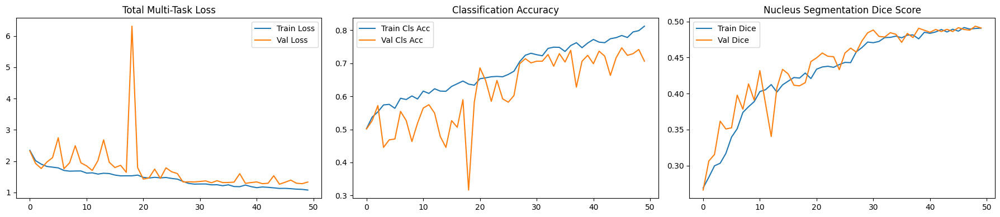


Final Test Classification Accuracy: 0.7475
Final Test Nucleus Segmentation Mean Dice Score: 0.4930

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.44      0.63      0.52        30
        HSIL       0.67      0.73      0.70       127
        LSIL       0.77      0.60      0.67        92
        NILM       1.00      1.00      1.00        92
         SCC       0.73      0.67      0.70        55

    accuracy                           0.75       396
   macro avg       0.72      0.73      0.72       396
weighted avg       0.76      0.75      0.75       396



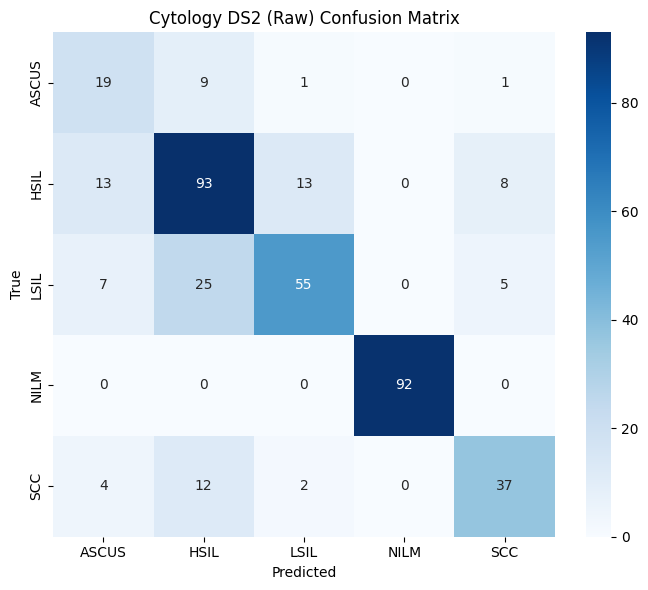

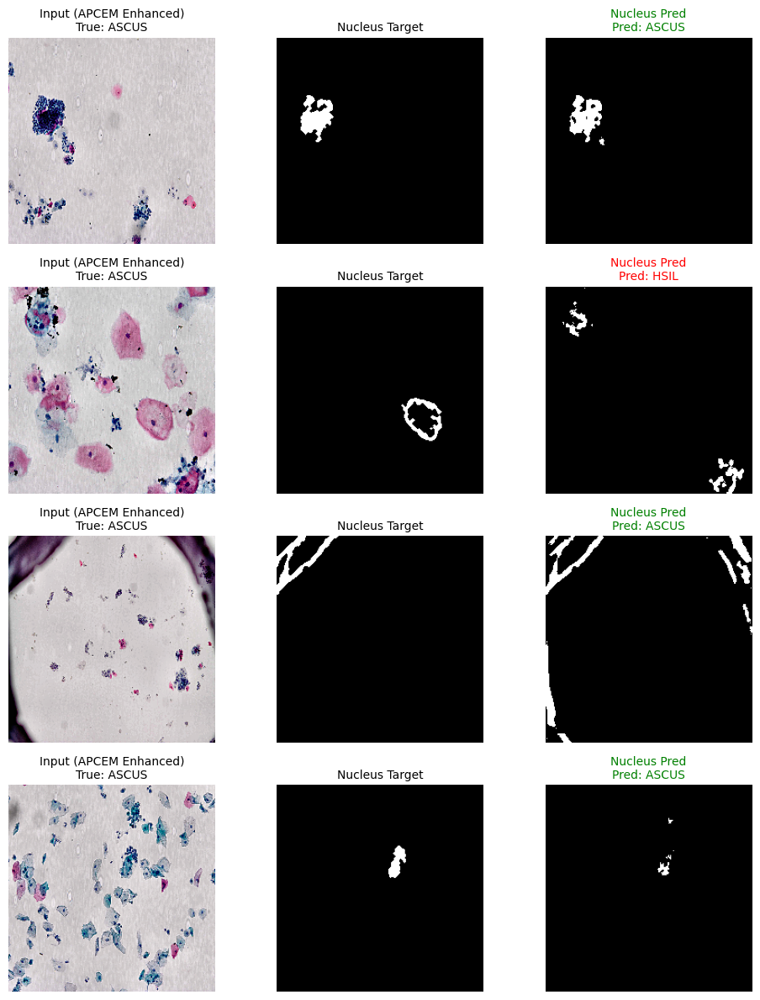

In [1]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_ds2_raw_multitask_data"
PLOTS_DIR = "plots_cytology_ds2_raw"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Images)
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, adaptive gamma, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive gamma correction based on image brightness
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 1.1 if brightness > 0.5 else 0.9
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Mild unsharp masking to preserve nuclear chromatin details
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """
    Extracts high-contrast nucleus masks from APCEM-enhanced images
    via adaptive thresholding and morphological filtering.
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Adaptive thresholding to segment dark, chromatin-rich nuclear regions
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    # Morphological filtering to isolate central nucleus
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    # Keep the largest central contour
    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Dataset Discovery, APCEM Processing & Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

all_records = []

for cls in BETHESDA_CLASSES:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    if os.path.exists(cls_dir):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_path in glob.glob(os.path.join(cls_dir, ext)):
                all_records.append((img_path, cls))

if len(all_records) == 0:
    raise RuntimeError(f"No images found in: {RAW_DATA_DIR}")

print(f"Discovered {len(all_records)} raw images across Bethesda classes: {BETHESDA_CLASSES}")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Applying APCEM and extracting nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        # Apply APCEM enhancement to raw image
        img_enhanced = apcem_preprocess(img_resized)
        img_enhanced_uint8 = (img_enhanced * 255.0).astype(np.uint8)

        # Extract nucleus mask from enhanced image
        mask = extract_nucleus_mask(img_enhanced_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_enhanced_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nAPCEM preprocessing and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Cytology Dataset 2 (Raw with APCEM)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_ds2_raw_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal model weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Cytology DS2 (Raw) Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input (APCEM Enhanced)\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_sample_inference.png", dpi=200)
plt.show()

NameError: name 'MultiTaskCytologyNet' is not defined

## Task 4: Merged Cytology Dataset 1 + 2 (Multi-Task Nucleus Segmentation & Classification).

Using compute device: cuda
Loaded 4134 pre-enhanced images from Dataset 1.
Loaded 2634 raw images from Dataset 2.

Total merged records: 6768 across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Processing and saving 4737 samples for 'train' split...
Processing and saving 1015 samples for 'val' split...
Processing and saving 1016 samples for 'test' split...

Merged dataset preparation and nucleus mask extraction complete.

Starting joint training on Merged Cytology Dataset (1+2)...
Epoch 01/50 | Train Loss: 2.2380 Acc: 0.474 Dice: 0.279 | Val Loss: 2.2783 Acc: 0.363 Dice: 0.289
Epoch 02/50 | Train Loss: 2.0020 Acc: 0.500 Dice: 0.305 | Val Loss: 1.9458 Acc: 0.540 Dice: 0.320
Epoch 03/50 | Train Loss: 1.8998 Acc: 0.537 Dice: 0.328 | Val Loss: 1.9482 Acc: 0.519 Dice: 0.356
Epoch 04/50 | Train Loss: 1.8640 Acc: 0.545 Dice: 0.350 | Val Loss: 2.0088 Acc: 0.477 Dice: 0.365
Epoch 05/50 | Train Loss: 1.7997 Acc: 0.559 Dice: 0.366 | Val Loss: 1.9944 Acc: 0.481 Dice: 0.371
Epoch 06/5

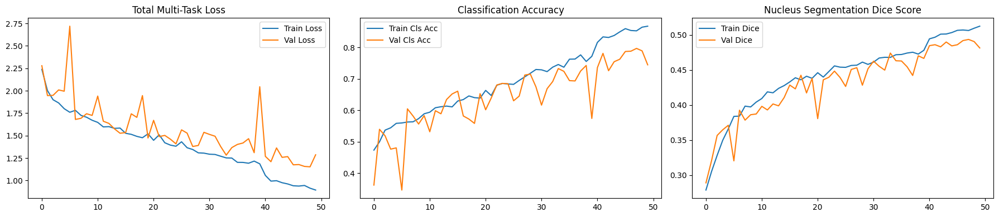


Final Test Classification Accuracy: 0.8179
Final Test Nucleus Segmentation Mean Dice Score: 0.4881

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.74      0.40      0.52        81
        HSIL       0.76      0.83      0.79       322
        LSIL       0.78      0.79      0.79       278
        NILM       0.96      0.97      0.96       209
         SCC       0.85      0.86      0.85       126

    accuracy                           0.82      1016
   macro avg       0.82      0.77      0.78      1016
weighted avg       0.82      0.82      0.81      1016



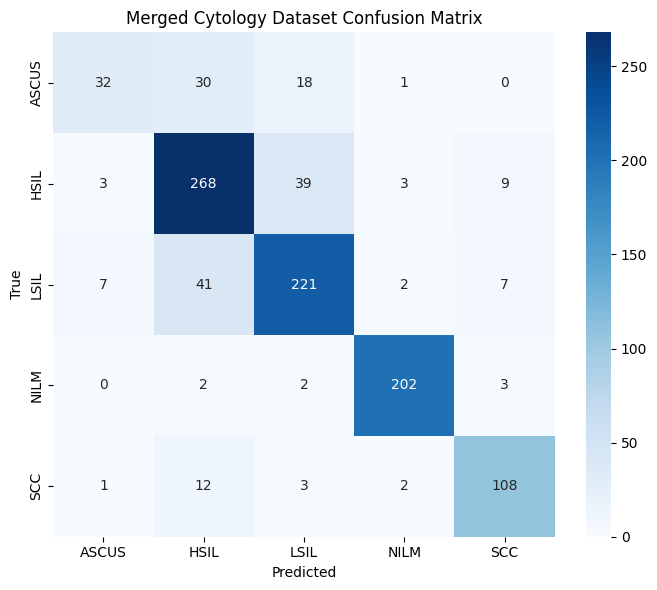

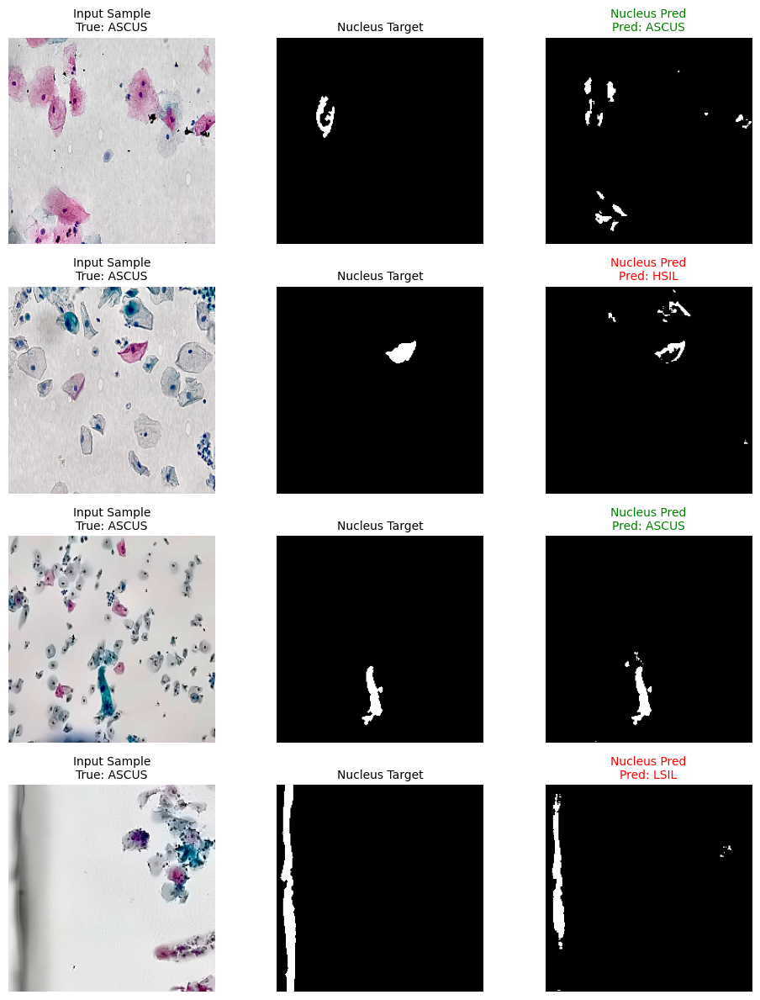

In [4]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_merged_multitask_data"
PLOTS_DIR = "plots_cytology_merged"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Samples)
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, adaptive gamma, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE in LAB space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive gamma correction
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Unsharp masking
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """Extracts high-contrast nucleus masks via adaptive thresholding and morphological filtering."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Discovery, Harmonization & Merged Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

ENHANCED_DATA_DIR = "/kaggle/input/datasets/abirbokhtiar/enhanced-cervical-cytology/Enhanced Cervical Cytology Image dataset"
RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"

all_records = []  # List of tuples: (image_path, class_name, needs_apcem)

# Collect from Dataset 1 (Enhanced - No APCEM needed)
if os.path.exists(ENHANCED_DATA_DIR):
    ds1_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(ENHANCED_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, False))
                    ds1_count += 1
    print(f"Loaded {ds1_count} pre-enhanced images from Dataset 1.")
else:
    print(f"Warning: Dataset 1 path not found: {ENHANCED_DATA_DIR}")

# Collect from Dataset 2 (Raw - APCEM will be applied)
if os.path.exists(RAW_DATA_DIR):
    ds2_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(RAW_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, True))
                    ds2_count += 1
    print(f"Loaded {ds2_count} raw images from Dataset 2.")
else:
    print(f"Warning: Dataset 2 path not found: {RAW_DATA_DIR}")

if len(all_records) == 0:
    raise RuntimeError("No images found across both datasets.")

print(f"\nTotal merged records: {len(all_records)} across Bethesda classes: {BETHESDA_CLASSES}")

# Unified Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Processing and saving {len(recs)} samples for '{split_name}' split...")
    for idx, (img_path, cls_name, apply_apcem) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        if apply_apcem:
            img_enhanced = apcem_preprocess(img_resized)
            img_final_uint8 = (img_enhanced * 255.0).astype(np.uint8)
        else:
            img_final_uint8 = img_resized

        # Extract high-contrast nucleus mask
        mask = extract_nucleus_mask(img_final_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{split_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_final_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nMerged dataset preparation and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.split("_")[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Merged Cytology Dataset (1+2)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_merged_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nRestored optimal model weights from validation loss checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Multi-Task Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Merged Cytology Dataset Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_merged_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input Sample\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_sample_inference.png", dpi=200)
plt.show()

## Task 5: Binary Classification on SIPAKMED (Normal vs Abnormal) + Nucleus Segmentation

Using compute device: cuda
Loaded 4049 total pairs for Binary Classification:
 - Normal: 1618 images
 - Abnormal: 2431 images
Rasterizing nucleus masks and saving 'train' split (2834 images)...
Rasterizing nucleus masks and saving 'val' split (607 images)...
Rasterizing nucleus masks and saving 'test' split (608 images)...

Binary dataset generation and mask rasterization complete.

Starting joint training on SIPAKMED Binary (Normal vs. Abnormal)...
Epoch 01/50 | Train Loss: 1.2878 Acc: 0.822 Dice: 0.534 | Val Loss: 1.1680 Acc: 0.848 Dice: 0.553
Epoch 02/50 | Train Loss: 0.9484 Acc: 0.862 Dice: 0.629 | Val Loss: 0.7930 Acc: 0.923 Dice: 0.623
Epoch 03/50 | Train Loss: 0.8160 Acc: 0.877 Dice: 0.680 | Val Loss: 0.7366 Acc: 0.918 Dice: 0.664
Epoch 04/50 | Train Loss: 0.7583 Acc: 0.895 Dice: 0.693 | Val Loss: 1.0749 Acc: 0.929 Dice: 0.429
Epoch 05/50 | Train Loss: 0.7272 Acc: 0.900 Dice: 0.708 | Val Loss: 0.8637 Acc: 0.848 Dice: 0.669
Epoch 06/50 | Train Loss: 0.7072 Acc: 0.900 Dice: 0.712 

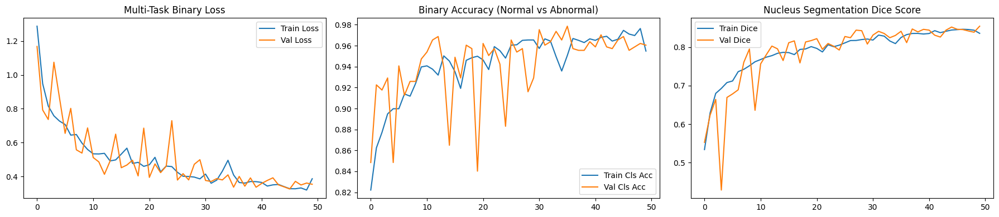


Final Test Binary Classification Accuracy: 0.9704
Final Test Nucleus Segmentation Mean Dice Score: 0.8357

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.95      0.96       243
    Abnormal       0.97      0.98      0.98       365

    accuracy                           0.97       608
   macro avg       0.97      0.97      0.97       608
weighted avg       0.97      0.97      0.97       608



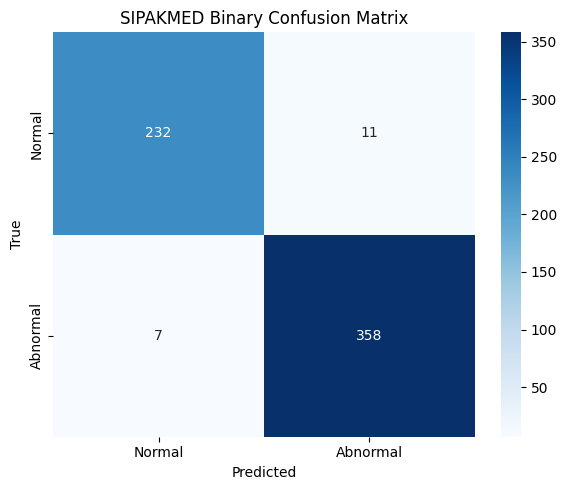

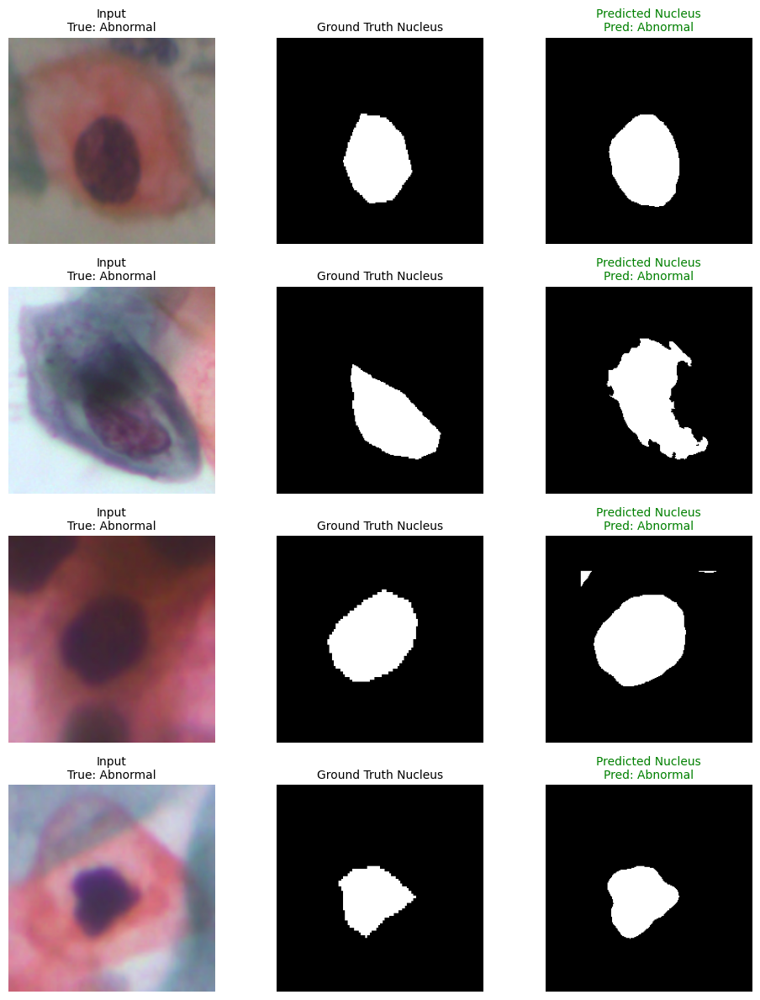

In [5]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "sipakmed_binary_multitask_data"
PLOTS_DIR = "plots_sipakmed_binary"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. Coordinate File Parser (.dat)
# ---------------------------------------------------------
def load_dat_coordinates(dat_path):
    """Parses polygon coordinate vertices from SIPAKMED .dat files."""
    coords = []
    if not os.path.exists(dat_path):
        return None
    with open(dat_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.replace(",", " ").split()
            if len(parts) >= 2:
                try:
                    coords.append([float(parts[0]), float(parts[1])])
                except ValueError:
                    continue
    if len(coords) == 0:
        return None
    return np.array(coords, dtype=np.int32)


# ---------------------------------------------------------
# 2. Dataset Discovery & Binary Mapping
# ---------------------------------------------------------
RAW_DATA_DIR = "/kaggle/input/datasets/fahmidaifty/sipakmed/SipakMed"
BINARY_CLASSES = ["Normal", "Abnormal"]

sipakmed_folders = [
    ("Normal/im_Superficial-Intermediate", "Normal"),
    ("Normal/im_Parabasal", "Normal"),
    ("Abnormal/im_Koilocytotic", "Abnormal"),
    ("Abnormal/im_Dyskeratotic", "Abnormal"),
    ("Abnormal/im_Metaplastic", "Abnormal")
]

all_pairs = []

for rel_path, binary_label in sipakmed_folders:
    search_dirs = [
        Path(RAW_DATA_DIR) / rel_path / "CROPPED",
        Path(RAW_DATA_DIR) / rel_path / rel_path / "CROPPED",
        Path(RAW_DATA_DIR) / rel_path
    ]

    for s_dir in search_dirs:
        if s_dir.exists():
            for bmp_path in s_dir.glob("*.bmp"):
                base_name = bmp_path.stem
                nuc_dat_path = s_dir / f"{base_name}_nuc.dat"
                if nuc_dat_path.exists():
                    all_pairs.append({
                        "bmp_path": str(bmp_path),
                        "nuc_dat": str(nuc_dat_path),
                        "class_name": binary_label,
                        "base_name": base_name
                    })

if len(all_pairs) == 0:
    raise RuntimeError(f"No matching image/_nuc.dat pairs found under {RAW_DATA_DIR}")

print(f"Loaded {len(all_pairs)} total pairs for Binary Classification:")
for b_cls in BINARY_CLASSES:
    c_count = sum(1 for p in all_pairs if p["class_name"] == b_cls)
    print(f" - {b_cls}: {c_count} images")

# Stratified 70% Train, 15% Val, 15% Test Split
pair_labels = [p["class_name"] for p in all_pairs]
train_pairs, temp_pairs = train_test_split(all_pairs, test_size=0.30, stratify=pair_labels, random_state=SEED)
temp_labels = [p["class_name"] for p in temp_pairs]
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_pairs, "val": val_pairs, "test": test_pairs}

for split_name, pairs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Rasterizing nucleus masks and saving '{split_name}' split ({len(pairs)} images)...")
    for idx, pair in enumerate(pairs):
        img = cv2.imread(pair["bmp_path"], cv2.IMREAD_COLOR)
        if img is None:
            continue
        h, w = img.shape[:2]

        nuc_mask = np.zeros((h, w), dtype=np.uint8)
        nuc_pts = load_dat_coordinates(pair["nuc_dat"])
        if nuc_pts is not None and len(nuc_pts) > 0:
            cv2.drawContours(nuc_mask, [nuc_pts], -1, 255, -1)

        img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        mask_resized = cv2.resize(nuc_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{pair['class_name']}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), img_resized)
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nBinary dataset generation and mask rasterization complete.")


# ---------------------------------------------------------
# 3. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class BinaryMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BINARY_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = BinaryMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = BinaryMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = BinaryMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 4. Multi-Task Residual Attention Network (2-Class Output)
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Binary Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 5. Losses & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=2).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 6. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on SIPAKMED Binary (Normal vs. Abnormal)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_sipakmed_binary_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal binary multitask weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 7. Evaluation & Visualizations
# ---------------------------------------------------------
model.eval()

# 1. Training Curves Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Multi-Task Binary Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Binary Accuracy (Normal vs Abnormal)")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/sipakmed_binary_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Binary Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BINARY_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BINARY_CLASSES, yticklabels=BINARY_CLASSES)
plt.title("SIPAKMED Binary Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/sipakmed_binary_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BINARY_CLASSES[sample_labels[i].item()]
    p_cls = BINARY_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Nucleus", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Predicted Nucleus\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/sipakmed_binary_sample_inference.png", dpi=200)
plt.show()

## Task 6: Custom Cytology Dataset (Normal vs. Abnormal) Multi-Task Nucleus Segmentation & Classification

Using compute device: cuda
Loaded 2782 total custom cytology images:
 - Normal: 1391 images
 - Abnormal: 1391 images
Applying APCEM & generating nucleus masks for 'train' split (1947 images)...
Applying APCEM & generating nucleus masks for 'val' split (417 images)...
Applying APCEM & generating nucleus masks for 'test' split (418 images)...

Custom cytology binary dataset preparation complete.

Starting joint training on Custom Cytology Binary Dataset (['Normal', 'Abnormal'])...
Epoch 01/50 | Train Loss: 1.5231 Acc: 0.839 Dice: 0.227 | Val Loss: 1.2602 Acc: 0.897 Dice: 0.264
Epoch 02/50 | Train Loss: 1.2160 Acc: 0.892 Dice: 0.267 | Val Loss: 1.7884 Acc: 0.564 Dice: 0.288
Epoch 03/50 | Train Loss: 1.1213 Acc: 0.905 Dice: 0.275 | Val Loss: 1.3076 Acc: 0.782 Dice: 0.256
Epoch 04/50 | Train Loss: 1.0947 Acc: 0.909 Dice: 0.284 | Val Loss: 1.9712 Acc: 0.602 Dice: 0.203
Epoch 05/50 | Train Loss: 1.0318 Acc: 0.932 Dice: 0.291 | Val Loss: 1.0106 Acc: 0.935 Dice: 0.305
Epoch 06/50 | Train Loss: 

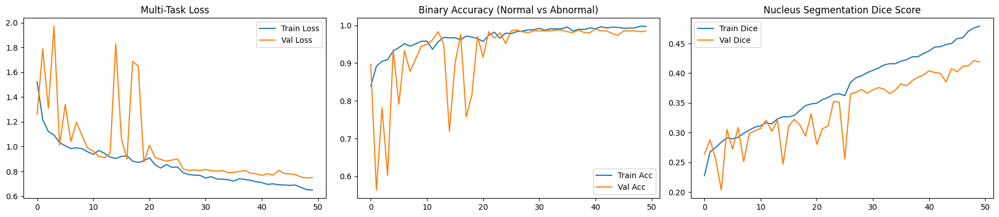


Final Test Binary Classification Accuracy: 0.9785
Final Test Nucleus Segmentation Mean Dice Score: 0.4337

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98       209
    Abnormal       0.97      0.99      0.98       209

    accuracy                           0.98       418
   macro avg       0.98      0.98      0.98       418
weighted avg       0.98      0.98      0.98       418



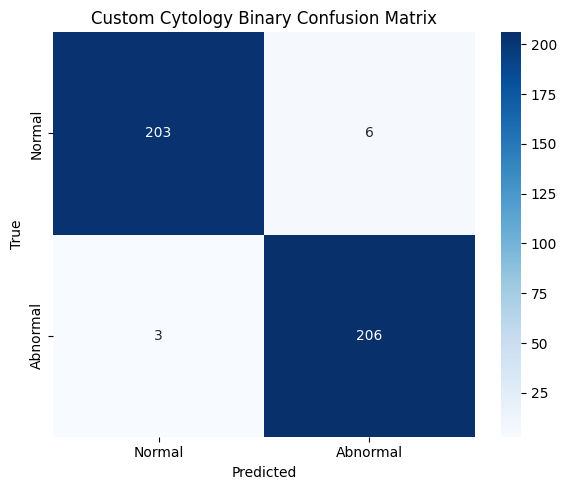

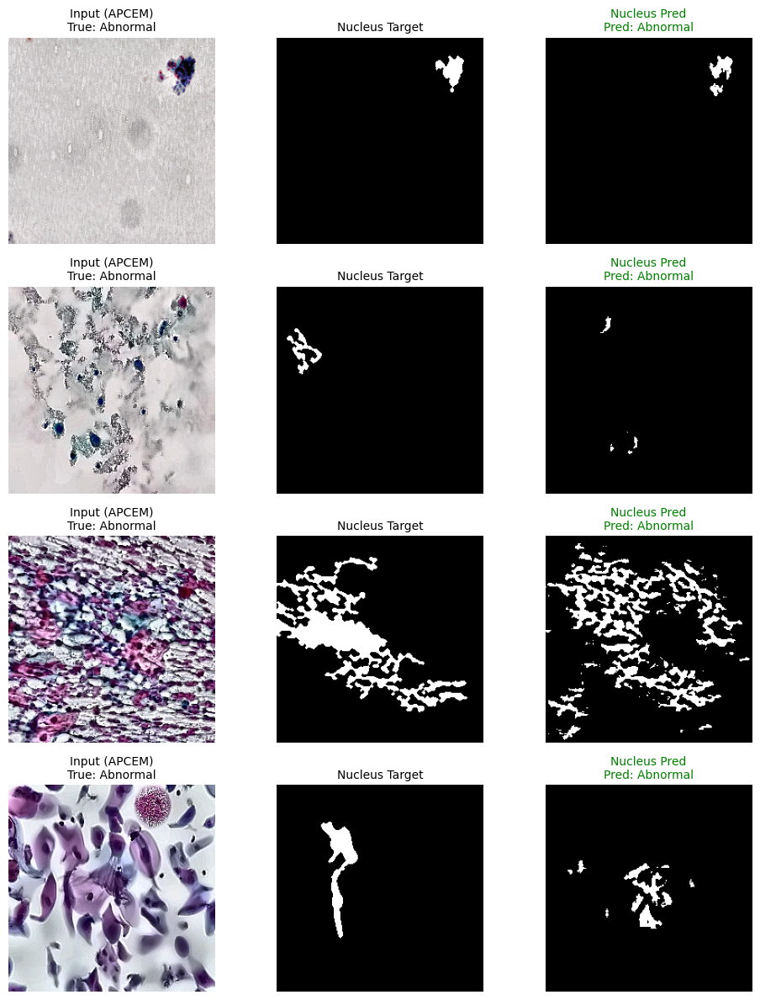

In [6]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Configurations & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "custom_cytology_binary_multitask_data"
PLOTS_DIR = "plots_custom_binary"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhances cytology images with CLAHE, adaptive gamma, and unsharp masking."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive gamma correction based on brightness
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Mild unsharp masking to sharpen chromatin borders
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """Extracts nuclear regions using adaptive thresholding and morphological cleanup."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Dataset Discovery, APCEM Processing & Stratified Split
# ---------------------------------------------------------
RAW_DATA_DIR = "/kaggle/input/datasets/fahmidaifty/custom-cervical-cancer-cytology-image/Renamed_Custom Cytology Dataset"
BINARY_CLASSES = ["Normal", "Abnormal"]

folder_mapping = {
    "Normal_Renamed": "Normal",
    "Abnormal_Renamed": "Abnormal"
}

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Directory not found: {RAW_DATA_DIR}")

all_records = []

for folder_name, binary_label in folder_mapping.items():
    folder_path = os.path.join(RAW_DATA_DIR, folder_name)
    if os.path.exists(folder_path):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_file in glob.glob(os.path.join(folder_path, ext)):
                all_records.append((img_file, binary_label))

if len(all_records) == 0:
    raise RuntimeError(f"No valid images found in {RAW_DATA_DIR}")

print(f"Loaded {len(all_records)} total custom cytology images:")
for b_cls in BINARY_CLASSES:
    c_count = sum(1 for _, label in all_records if label == b_cls)
    print(f" - {b_cls}: {c_count} images")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [label for _, label in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [label for _, label in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Applying APCEM & generating nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        # Apply APCEM enhancement
        img_enhanced = apcem_preprocess(img_resized)
        img_enhanced_uint8 = (img_enhanced * 255.0).astype(np.uint8)

        # Extract nucleus mask
        mask = extract_nucleus_mask(img_enhanced_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{split_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_enhanced_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nCustom cytology binary dataset preparation complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CustomBinaryMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BINARY_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.split("_")[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CustomBinaryMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CustomBinaryMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CustomBinaryMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network Architecture
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Bottleneck Self-Attention
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Binary Classification Head
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=2).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Custom Cytology Binary Dataset ({BINARY_CLASSES})...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_custom_binary_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nLoaded optimal checkpoint weights based on validation loss.")


# ---------------------------------------------------------
# 8. Evaluation, Performance Curves & Predictions
# ---------------------------------------------------------
model.eval()

# 1. Multi-Task Training Curves Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Acc")
axes[1].plot(history["val_cls_acc"], label="Val Acc")
axes[1].set_title("Binary Accuracy (Normal vs Abnormal)")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/custom_binary_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Binary Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BINARY_CLASSES, zero_division=0))

# 3. Confusion Matrix Plot
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BINARY_CLASSES, yticklabels=BINARY_CLASSES)
plt.title("Custom Cytology Binary Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/custom_binary_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions (Input | Target Mask | Predicted Mask)
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BINARY_CLASSES[sample_labels[i].item()]
    p_cls = BINARY_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input (APCEM)\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/custom_binary_sample_inference.png", dpi=200)
plt.show()

# Classification (16 August)

# custom-cervical-cancer-cytology-image Dataset classification

Using compute device: cuda
Found 1391 images for class 'Abnormal' (Abnormal_Renamed)
Found 1391 images for class 'Normal' (Normal_Renamed)

Discovered classes: ['Abnormal', 'Normal'] (Total images: 2782)
Processing and enhancing 1947 images for 'train' split...
Processing and enhancing 417 images for 'val' split...
Processing and enhancing 418 images for 'test' split...

Data preprocessing complete.

Starting training for 20 epochs on ['Abnormal', 'Normal']...
Epoch 01/20 | Train Loss: 0.3407 Acc: 0.8649 | Val Loss: 0.1770 Acc: 0.9353
Epoch 02/20 | Train Loss: 0.2396 Acc: 0.9147 | Val Loss: 0.1136 Acc: 0.9544
Epoch 03/20 | Train Loss: 0.2181 Acc: 0.9168 | Val Loss: 0.1808 Acc: 0.9376
Epoch 04/20 | Train Loss: 0.1626 Acc: 0.9404 | Val Loss: 0.4360 Acc: 0.8657
Epoch 05/20 | Train Loss: 0.1640 Acc: 0.9409 | Val Loss: 0.1136 Acc: 0.9544
Epoch 06/20 | Train Loss: 0.1426 Acc: 0.9450 | Val Loss: 0.0699 Acc: 0.9808
Epoch 07/20 | Train Loss: 0.1297 Acc: 0.9563 | Val Loss: 0.1189 Acc: 0.9520
Epo

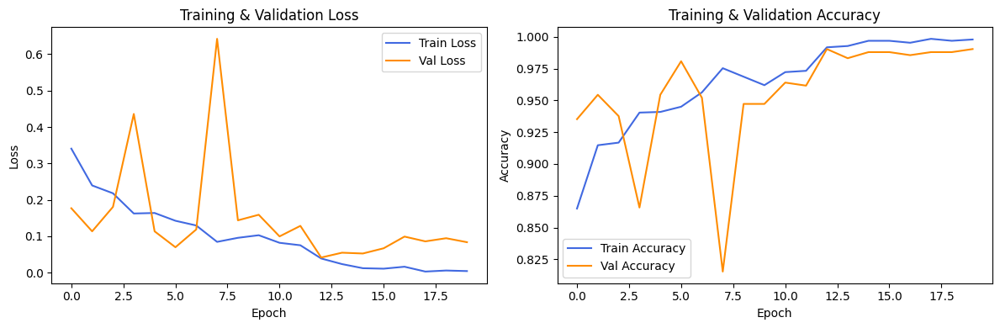


Final Test Accuracy: 0.9833

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.97      1.00      0.98       209
      Normal       1.00      0.97      0.98       209

    accuracy                           0.98       418
   macro avg       0.98      0.98      0.98       418
weighted avg       0.98      0.98      0.98       418



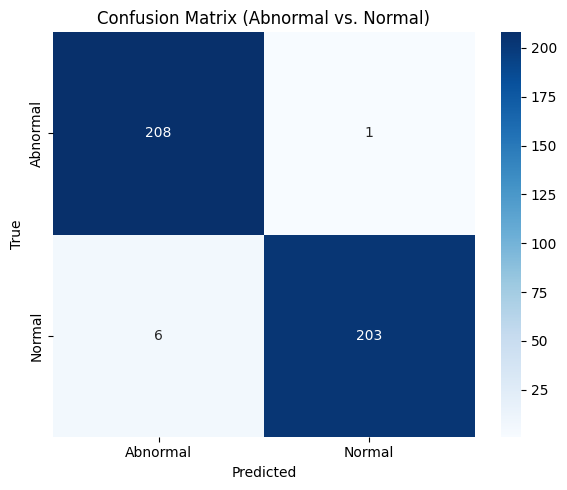

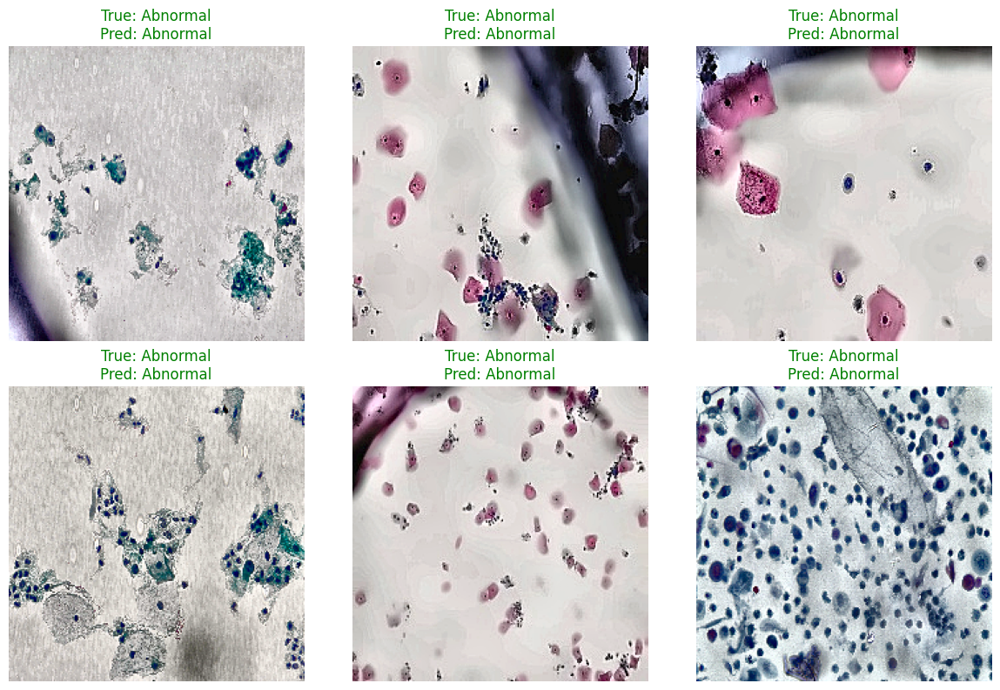

In [1]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 20
LEARNING_RATE = 1e-3
OUTPUT_DIR = "binary_data"
PLOTS_DIR = "plots"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Preprocessing Function
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance cytology images with local contrast, adaptive gamma, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive gamma correction based on image brightness
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Mild unsharp masking
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Dataset Loader & Stratified Split
# ---------------------------------------------------------
RAW_DATA_DIR = "/kaggle/input/datasets/fahmidaifty/custom-cervical-cancer-cytology-image/Renamed_Custom Cytology Dataset"

class_mapping = {
    "Abnormal_Renamed": "Abnormal",
    "Normal_Renamed": "Normal"
}

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset directory not found: {RAW_DATA_DIR}")

image_records = []  # List of tuples: (image_path, canonical_label)

for folder_name, canonical_name in class_mapping.items():
    folder_path = os.path.join(RAW_DATA_DIR, folder_name)
    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found -> {folder_path}")
        continue

    found_count = 0
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
        for img_file in glob.glob(os.path.join(folder_path, ext)):
            image_records.append((img_file, canonical_name))
            found_count += 1

    print(f"Found {found_count} images for class '{canonical_name}' ({folder_name})")

if len(image_records) == 0:
    raise ValueError(f"No images discovered in {RAW_DATA_DIR}. Please check the folder paths.")

target_classes = sorted(list(set(label for _, label in image_records)))
print(f"\nDiscovered classes: {target_classes} (Total images: {len(image_records)})")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [label for _, label in image_records]
train_rec, temp_rec = train_test_split(image_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [label for _, label in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

# Create directories and preprocess images
for split_name, records in splits.items():
    for cls in target_classes:
        os.makedirs(os.path.join(OUTPUT_DIR, split_name, cls), exist_ok=True)

    print(f"Processing and enhancing {len(records)} images for '{split_name}' split...")
    for idx, (img_path, cls) in enumerate(records):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        img_enhanced = apcem_preprocess(img)

        img_to_save = (img_enhanced * 255.0).astype(np.uint8)
        dst_path = os.path.join(OUTPUT_DIR, split_name, cls, f"{split_name}_{idx:06d}.png")
        cv2.imwrite(dst_path, cv2.cvtColor(img_to_save, cv2.COLOR_RGB2BGR))

print("\nData preprocessing complete.")


# ---------------------------------------------------------
# 3. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyDataset(Dataset):
    def __init__(self, data_root, split="train"):
        self.split_dir = Path(data_root) / split
        self.class_names = target_classes
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for class_name in self.class_names:
            class_dir = self.split_dir / class_name
            if class_dir.exists():
                for img_path in class_dir.glob("*.png"):
                    self.samples.append((str(img_path), self.class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)  # [H, W, C] -> [C, H, W]
        return torch.from_numpy(img).float(), torch.tensor(label, dtype=torch.long)


train_ds = CytologyDataset(OUTPUT_DIR, "train")
val_ds = CytologyDataset(OUTPUT_DIR, "val")
test_ds = CytologyDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 4. Residual Attention CNN Architecture
# ---------------------------------------------------------
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.proj = None
        if stride != 1 or in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        residual = self.proj(x) if self.proj is not None else x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return F.relu(x + residual)


class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1, padding=0)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(residual + self.proj(attn_out))


class ResidualAttentionCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.block1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.block2 = ResidualBlock(32, 64, stride=2)
        self.attn2 = AttentionBlock(64)
        self.pool2 = nn.MaxPool2d(2)

        self.block3 = ResidualBlock(64, 128, stride=2)
        self.attn3 = AttentionBlock(128)
        self.pool3 = nn.MaxPool2d(2)

        self.block4 = ResidualBlock(128, 256, stride=2)
        self.attn4 = AttentionBlock(256)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.attn2(self.block2(x)))
        x = self.pool3(self.attn3(self.block3(x)))
        x = self.attn4(self.block4(x))
        x = self.gap(x).flatten(1)
        x = self.fc1(x)
        return self.fc2(x)


model = ResidualAttentionCNN(num_classes=len(target_classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 5. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
train_history = {"loss": [], "accuracy": []}
val_history = {"loss": [], "accuracy": []}

print(f"\nStarting training for {NUM_EPOCHS} epochs on {target_classes}...")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == targets).sum().item()
        train_total += targets.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total
    train_history["loss"].append(train_loss)
    train_history["accuracy"].append(train_acc)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            loss = criterion(logits, targets)

            val_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == targets).sum().item()
            val_total += targets.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_history["loss"].append(val_loss)
    val_history["accuracy"].append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch {epoch + 1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_binary_residual_attention_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nBest model weights loaded based on validation loss.")


# ---------------------------------------------------------
# 6. Evaluation, Performance Plots & Predictions
# ---------------------------------------------------------
model.eval()

# 1. Loss & Accuracy History Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_history["loss"], label="Train Loss", color="royalblue")
axes[0].plot(val_history["loss"], label="Val Loss", color="darkorange")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(train_history["accuracy"], label="Train Accuracy", color="royalblue")
axes[1].plot(val_history["accuracy"], label="Val Accuracy", color="darkorange")
axes[1].set_title("Training & Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/binary_training_history.png", dpi=200)
plt.show()

# 2. Test Set Inference
all_true, all_pred = [], []
with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_true.extend(targets.numpy().tolist())
        all_pred.extend(preds.tolist())

print(f"\nFinal Test Accuracy: {accuracy_score(all_true, all_pred):.4f}")
print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=target_classes, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_classes,
    yticklabels=target_classes,
)
plt.title("Confusion Matrix (Abnormal vs. Normal)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/binary_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_images, sample_targets = next(iter(test_loader))
sample_images_dev = sample_images.to(device)
with torch.no_grad():
    sample_preds = model(sample_images_dev).argmax(dim=1).cpu().numpy()

sample_images_np = sample_images.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_images_np):
        break
    ax.imshow(np.clip(sample_images_np[i], 0, 1))
    t_label = target_classes[sample_targets[i].item()]
    p_label = target_classes[sample_preds[i]]
    is_correct = t_label == p_label
    ax.set_title(f"True: {t_label}\nPred: {p_label}", color="green" if is_correct else "red")
    ax.axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/binary_sample_predictions.png", dpi=200)
plt.show()

# Merged CytologicalCervicalCancer + CytologicalCervicalCancer(raw) Dataset classification

Using compute device: cuda
Loaded 2634 images from Raw Dataset (APCEM will be applied).
Loaded 4134 images from Enhanced Dataset (Preprocessed).

Total merged samples collected: 6768
Processing and saving 'train' split (4737 images)...
Processing and saving 'val' split (1015 images)...
Processing and saving 'test' split (1016 images)...

All images processed and organized into canonical directories.

Starting training for 50 epochs on classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Epoch 01/50 | Train Loss: 1.1900 Acc: 0.4931 | Val Loss: 1.1806 Acc: 0.4946
Epoch 02/50 | Train Loss: 1.0338 Acc: 0.5622 | Val Loss: 1.1495 Acc: 0.5547
Epoch 03/50 | Train Loss: 0.9640 Acc: 0.6010 | Val Loss: 0.9586 Acc: 0.5872
Epoch 04/50 | Train Loss: 0.8867 Acc: 0.6268 | Val Loss: 0.9386 Acc: 0.5980
Epoch 05/50 | Train Loss: 0.8440 Acc: 0.6458 | Val Loss: 0.7951 Acc: 0.6966
Epoch 06/50 | Train Loss: 0.7797 Acc: 0.6711 | Val Loss: 1.0371 Acc: 0.6049
Epoch 07/50 | Train Loss: 0.7393 Acc: 0.6956 | Val Loss

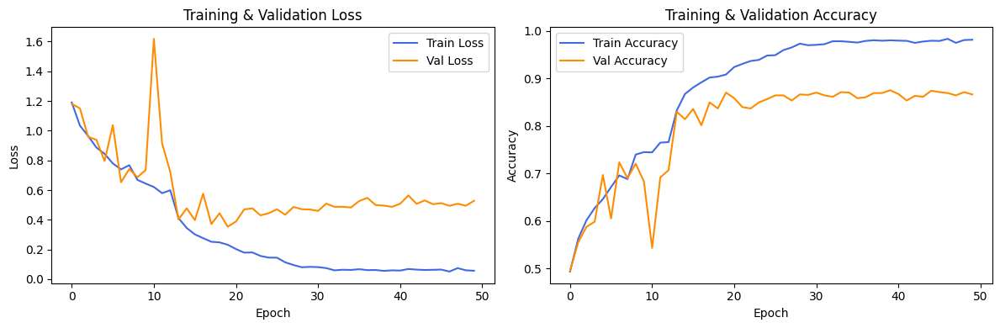


Final Test Accuracy: 0.8376

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.87      0.58      0.70        81
        HSIL       0.80      0.81      0.80       322
        LSIL       0.79      0.82      0.80       278
        NILM       0.97      0.97      0.97       209
         SCC       0.83      0.90      0.86       126

    accuracy                           0.84      1016
   macro avg       0.85      0.82      0.83      1016
weighted avg       0.84      0.84      0.84      1016



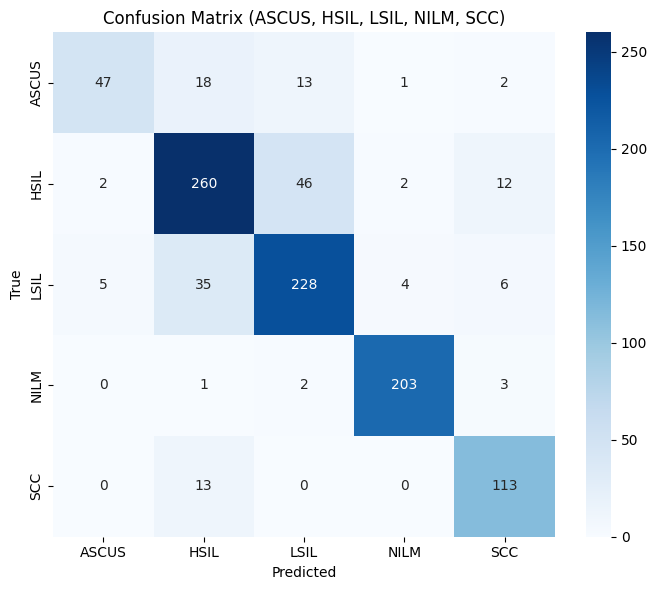

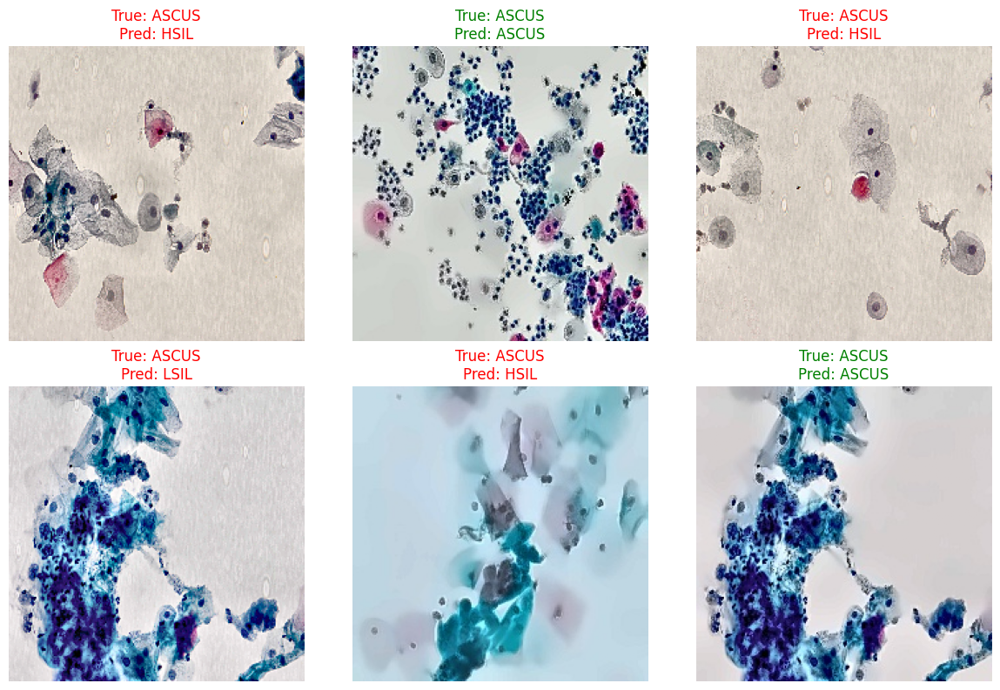

In [1]:
import os
import glob
import math
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Seed Configuration
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "merged_data"
PLOTS_DIR = "plots"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Images)
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhances cytology images with CLAHE, adaptive gamma, and sharpening."""
    img = image.astype(np.float32)
    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive Gamma correction
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Mild unsharp masking
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Dataset Paths & Unified Class Mapping
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

RAW_DATASET_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"
ENHANCED_DATASET_DIR = "/kaggle/input/datasets/abirbokhtiar/enhanced-cervical-cytology/Enhanced Cervical Cytology Image dataset"

all_records = []  # Tuples: (image_path, class_name, needs_apcem_flag)

# --- 2A. Load Raw Dataset (Needs APCEM) ---
if os.path.exists(RAW_DATASET_DIR):
    raw_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(RAW_DATASET_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, True))
                    raw_count += 1
    print(f"Loaded {raw_count} images from Raw Dataset (APCEM will be applied).")
else:
    print(f"Warning: Raw dataset path not found: {RAW_DATASET_DIR}")

# --- 2B. Load Already Enhanced Dataset (Direct Resize & Normalize) ---
if os.path.exists(ENHANCED_DATASET_DIR):
    enhanced_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(ENHANCED_DATASET_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, False))
                    enhanced_count += 1
    print(f"Loaded {enhanced_count} images from Enhanced Dataset (Preprocessed).")
else:
    print(f"Warning: Enhanced dataset path not found: {ENHANCED_DATASET_DIR}")

if len(all_records) == 0:
    raise RuntimeError("No images found. Please verify the dataset paths in your environment.")

print(f"\nTotal merged samples collected: {len(all_records)}")


# ---------------------------------------------------------
# 3. Stratified Split (70% Train, 15% Val, 15% Test)
# ---------------------------------------------------------
labels = [r[1] for r in all_records]

train_recs, temp_recs = train_test_split(
    all_records, test_size=0.30, stratify=labels, random_state=SEED
)
temp_labels = [r[1] for r in temp_recs]

val_recs, test_recs = train_test_split(
    temp_recs, test_size=0.50, stratify=temp_labels, random_state=SEED
)

splits = {"train": train_recs, "val": val_recs, "test": test_recs}

for split_name, recs in splits.items():
    for cls in BETHESDA_CLASSES:
        os.makedirs(os.path.join(OUTPUT_DIR, split_name, cls), exist_ok=True)

    print(f"Processing and saving '{split_name}' split ({len(recs)} images)...")
    for idx, (src_path, cls, apply_apcem) in enumerate(recs):
        img = cv2.imread(src_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        if apply_apcem:
            img = apcem_preprocess(img)
            img_to_save = (img * 255.0).astype(np.uint8)
        else:
            img_to_save = img

        dst_path = os.path.join(OUTPUT_DIR, split_name, cls, f"{split_name}_{idx:06d}.png")
        cv2.imwrite(dst_path, cv2.cvtColor(img_to_save, cv2.COLOR_RGB2BGR))

print("\nAll images processed and organized into canonical directories.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CervicalCytologyDataset(Dataset):
    def __init__(self, data_root, split="train"):
        self.split_dir = Path(data_root) / split
        self.class_names = BETHESDA_CLASSES
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for class_name in self.class_names:
            class_folder = self.split_dir / class_name
            if class_folder.exists():
                for img_path in class_folder.glob("*.png"):
                    self.samples.append((str(img_path), self.class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)  # [H, W, C] -> [C, H, W]
        return torch.from_numpy(img).float(), torch.tensor(label, dtype=torch.long)


train_ds = CervicalCytologyDataset(OUTPUT_DIR, "train")
val_ds = CervicalCytologyDataset(OUTPUT_DIR, "val")
test_ds = CervicalCytologyDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Residual Attention CNN Architecture
# ---------------------------------------------------------
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.proj = None
        if stride != 1 or in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        residual = self.proj(x) if self.proj is not None else x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return F.relu(x + residual)


class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1, padding=0)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(residual + self.proj(attn_out))


class ResidualAttentionCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.block1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.block2 = ResidualBlock(32, 64, stride=2)
        self.attn2 = AttentionBlock(64)
        self.pool2 = nn.MaxPool2d(2)

        self.block3 = ResidualBlock(64, 128, stride=2)
        self.attn3 = AttentionBlock(128)
        self.pool3 = nn.MaxPool2d(2)

        self.block4 = ResidualBlock(128, 256, stride=2)
        self.attn4 = AttentionBlock(256)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.attn2(self.block2(x)))
        x = self.pool3(self.attn3(self.block3(x)))
        x = self.attn4(self.block4(x))
        x = self.gap(x).flatten(1)
        x = self.fc1(x)
        return self.fc2(x)


model = ResidualAttentionCNN(num_classes=len(BETHESDA_CLASSES)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)

# ---------------------------------------------------------
# 6. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
train_history = {"loss": [], "accuracy": []}
val_history = {"loss": [], "accuracy": []}

print(f"\nStarting training for {NUM_EPOCHS} epochs on classes: {BETHESDA_CLASSES}")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == targets).sum().item()
        train_total += targets.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total
    train_history["loss"].append(train_loss)
    train_history["accuracy"].append(train_acc)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            loss = criterion(logits, targets)

            val_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == targets).sum().item()
            val_total += targets.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_history["loss"].append(val_loss)
    val_history["accuracy"].append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch {epoch + 1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_bethesda_residual_attention_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nRestored best model weights based on validation loss.")


# ---------------------------------------------------------
# 7. Model Evaluation & Plots
# ---------------------------------------------------------
model.eval()

# 1. Loss & Accuracy History Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_history["loss"], label="Train Loss", color="royalblue")
axes[0].plot(val_history["loss"], label="Val Loss", color="darkorange")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(train_history["accuracy"], label="Train Accuracy", color="royalblue")
axes[1].plot(val_history["accuracy"], label="Val Accuracy", color="darkorange")
axes[1].set_title("Training & Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/bethesda_training_history.png", dpi=200)
plt.show()

# 2. Test Set Inference
all_true, all_pred = [], []
with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_true.extend(targets.numpy().tolist())
        all_pred.extend(preds.tolist())

print(f"\nFinal Test Accuracy: {accuracy_score(all_true, all_pred):.4f}")
print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=BETHESDA_CLASSES,
    yticklabels=BETHESDA_CLASSES,
)
plt.title("Confusion Matrix (ASCUS, HSIL, LSIL, NILM, SCC)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/bethesda_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_images, sample_targets = next(iter(test_loader))
sample_images_dev = sample_images.to(device)
with torch.no_grad():
    sample_preds = model(sample_images_dev).argmax(dim=1).cpu().numpy()

sample_images_np = sample_images.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_images_np):
        break
    ax.imshow(np.clip(sample_images_np[i], 0, 1))
    t_label = BETHESDA_CLASSES[sample_targets[i].item()]
    p_label = BETHESDA_CLASSES[sample_preds[i]]
    is_correct = t_label == p_label
    ax.set_title(f"True: {t_label}\nPred: {p_label}", color="green" if is_correct else "red")
    ax.axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/bethesda_sample_predictions.png", dpi=200)
plt.show()

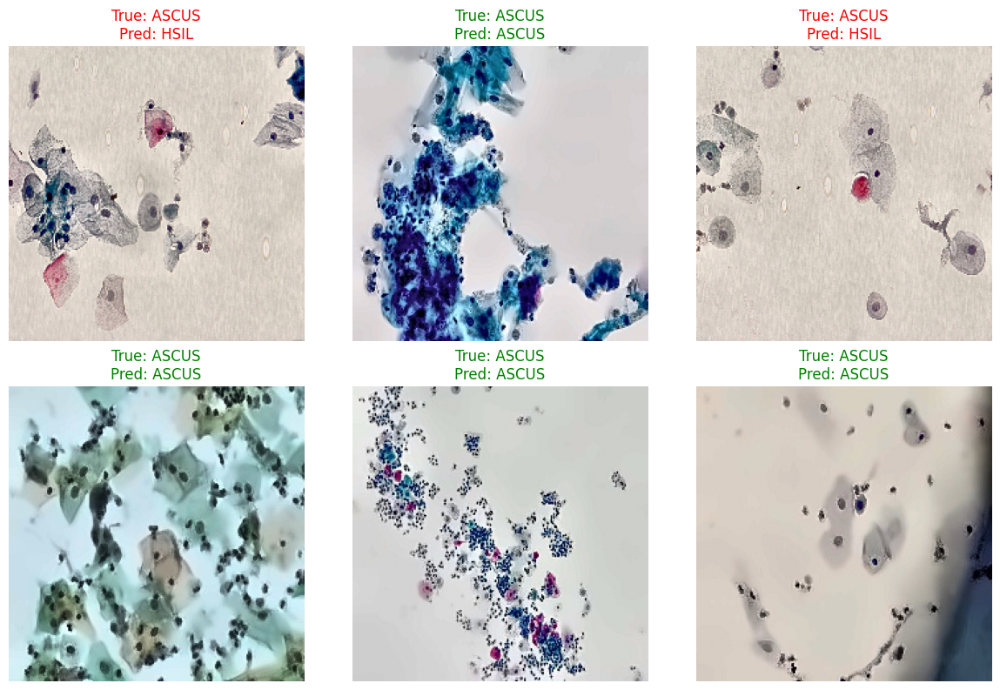

In [6]:
# 4. Sample Test Predictions Visualization
import numpy as np

# Fetch the first batch
sample_images, sample_targets = next(iter(test_loader))

# Pick 6 random indices from this batch
batch_size = sample_images.size(0)
random_indices = np.random.choice(batch_size, size=6, replace=False)

# Filter the batch using the random indices
sample_images = sample_images[random_indices]
sample_targets = sample_targets[random_indices]

# Run inference
sample_images_dev = sample_images.to(device)
with torch.no_grad():
    sample_preds = model(sample_images_dev).argmax(dim=1).cpu().numpy()


sample_images_np = sample_images.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_images_np):
        break
    ax.imshow(np.clip(sample_images_np[i], 0, 1))
    t_label = BETHESDA_CLASSES[sample_targets[i].item()]
    p_label = BETHESDA_CLASSES[sample_preds[i]]
    is_correct = t_label == p_label
    ax.set_title(f"True: {t_label}\nPred: {p_label}", color="green" if is_correct else "red")
    ax.axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/bethesda_sample_predictions.png", dpi=200)
plt.show()

# Merged CIPAKMED + CytologicalCervicalCancer(raw) Dataset classification

Using compute device: cuda
Dataset 1 loaded: 2634 images found.
Dataset 2 loaded: 4049 images found.

Canonicalized Unified Classes: ['ascus', 'dyskeratotic', 'hsil', 'koilocytotic', 'lsil', 'metaplastic', 'nilm', 'parabasal', 'scc', 'superficial_intermediate']
Saving and processing 4678 images for 'train' split...
Saving and processing 1002 images for 'val' split...
Saving and processing 1003 images for 'test' split...

Dataset preparation completed successfully.

Starting training on 10 classes: ['ascus', 'dyskeratotic', 'hsil', 'koilocytotic', 'lsil', 'metaplastic', 'nilm', 'parabasal', 'scc', 'superficial_intermediate']
Epoch 01/50 | Train Loss: 1.1896 Acc: 0.5492 | Val Loss: 1.1299 Acc: 0.6098
Epoch 02/50 | Train Loss: 0.8295 Acc: 0.6877 | Val Loss: 1.1313 Acc: 0.6168
Epoch 03/50 | Train Loss: 0.7543 Acc: 0.7165 | Val Loss: 0.6424 Acc: 0.7485
Epoch 04/50 | Train Loss: 0.6876 Acc: 0.7388 | Val Loss: 0.6435 Acc: 0.7615
Epoch 05/50 | Train Loss: 0.6463 Acc: 0.7495 | Val Loss: 0.7498 

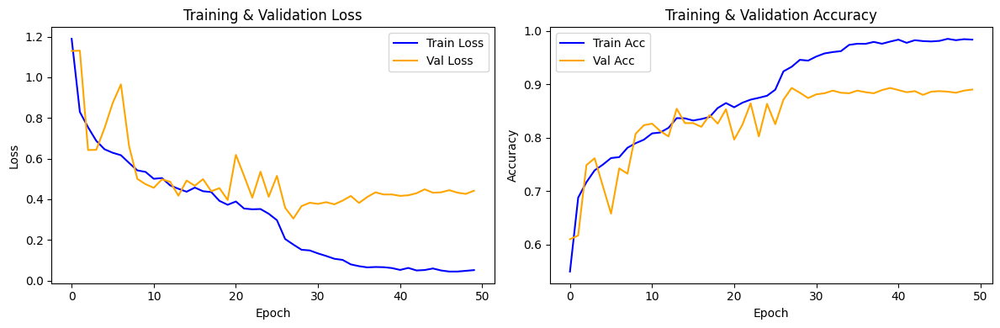


Final Test Accuracy: 0.9153

Classification Report:
                          precision    recall  f1-score   support

                   ascus       0.73      0.55      0.63        29
            dyskeratotic       0.97      0.97      0.97       122
                    hsil       0.78      0.85      0.81       127
            koilocytotic       0.97      0.90      0.93       124
                    lsil       0.87      0.79      0.83        92
             metaplastic       0.94      0.97      0.95       119
                    nilm       0.98      1.00      0.99        92
               parabasal       1.00      0.97      0.99       118
                     scc       0.82      0.84      0.83        55
superficial_intermediate       0.92      0.98      0.95       125

                accuracy                           0.92      1003
               macro avg       0.90      0.88      0.89      1003
            weighted avg       0.92      0.92      0.91      1003



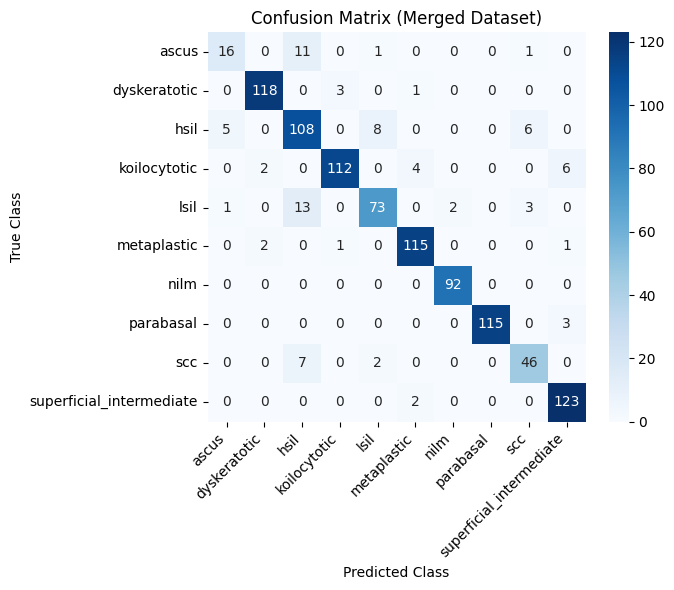

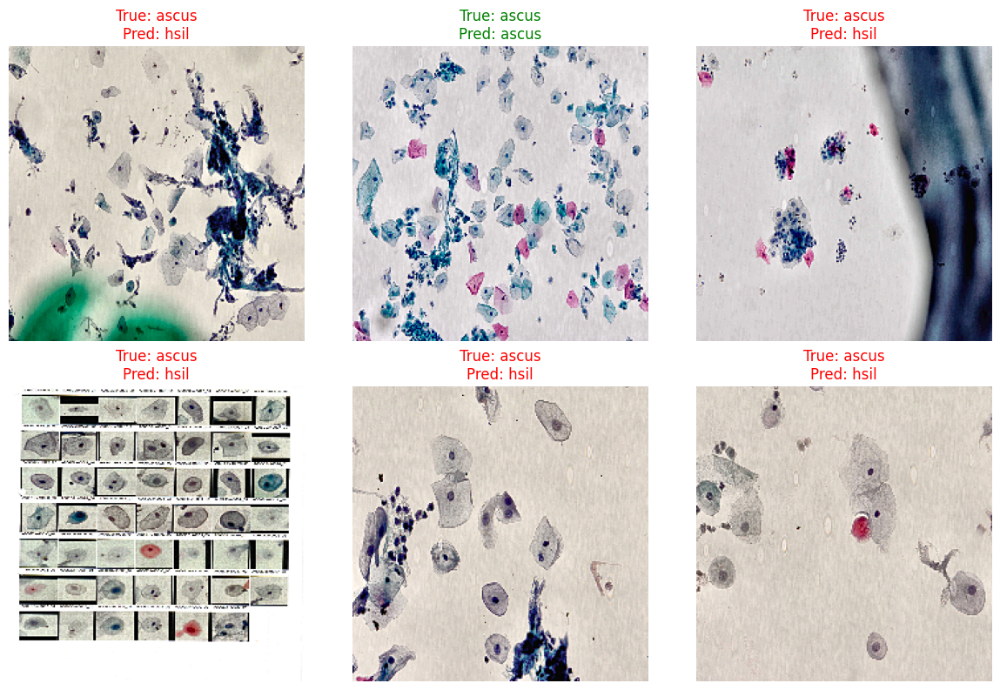

In [1]:
import os
import glob
import shutil
import math
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Configurations & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "data"
PLOTS_DIR = "plots"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM: Adaptive Parameterized Cytology Enhancement Model
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance cytology images with CLAHE, adaptive gamma, and mild sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. Contrast enhancement via CLAHE in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Adaptive gamma correction based on image brightness
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # 3. Mild unsharp masking to preserve nuclear and cytoplasmic detail
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Canonical Class Name Normalizer
# ---------------------------------------------------------
def canonicalize_class_name(raw_name: str) -> str:
    """Standardizes folder names to ensure exact matches across both datasets."""
    name = os.path.basename(raw_name).lower().strip()
    if name.startswith("im_"):
        name = name[3:]
    name = name.replace("-", "_").replace(" ", "_")
    return name


# ---------------------------------------------------------
# 3. Dataset Discovery, Merging & Alignment
# ---------------------------------------------------------
DATASET_1_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"
DATASET_2_DIR = "/kaggle/input/datasets/fahmidaifty/sipakmed/SipakMed"

all_records = []  # List of tuples: (image_path, canonical_label, needs_apcem)

# --- Collect from Dataset 1 (Raw -> Requires APCEM) ---
if os.path.exists(DATASET_1_DIR):
    class_dirs_ds1 = [p for p in Path(DATASET_1_DIR).iterdir() if p.is_dir()]
    for c_dir in class_dirs_ds1:
        canon_cls = canonicalize_class_name(c_dir.name)
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
            for img_path in c_dir.glob(ext):
                all_records.append((str(img_path), canon_cls, True))
    print(f"Dataset 1 loaded: {len(all_records)} images found.")
else:
    print(f"Dataset 1 directory not found: {DATASET_1_DIR}")

# --- Collect from Dataset 2 (Already Preprocessed or SIPAKMED standard format) ---
count_before_ds2 = len(all_records)
if os.path.exists(DATASET_2_DIR):
    sipakmed_subpaths = [
        "Normal/im_Superficial-Intermediate",
        "Normal/im_Parabasal",
        "Abnormal/im_Koilocytotic",
        "Abnormal/im_Dyskeratotic",
        "Abnormal/im_Metaplastic"
    ]
    for rel_path in sipakmed_subpaths:
        canon_cls = canonicalize_class_name(rel_path)
        
        # Check both direct subfolder and nested CROPPED subfolder
        search_dirs = [
            Path(DATASET_2_DIR) / rel_path / "CROPPED",
            Path(DATASET_2_DIR) / rel_path / rel_path / "CROPPED",
            Path(DATASET_2_DIR) / rel_path
        ]
        
        found_for_class = 0
        for s_dir in search_dirs:
            if s_dir.exists():
                for ext in ("*.bmp", "*.png", "*.jpg", "*.jpeg"):
                    for img_path in s_dir.glob(ext):
                        all_records.append((str(img_path), canon_cls, False))
                        found_for_class += 1
                if found_for_class > 0:
                    break

    print(f"Dataset 2 loaded: {len(all_records) - count_before_ds2} images found.")
else:
    print(f"Dataset 2 directory not found: {DATASET_2_DIR}")

if len(all_records) == 0:
    raise RuntimeError("No images discovered. Please verify dataset paths.")

unique_classes = sorted(list(set(label for _, label, _ in all_records)))
print("\nCanonicalized Unified Classes:", unique_classes)

# ---------------------------------------------------------
# 4. Stratified Split (70% Train, 15% Val, 15% Test)
# ---------------------------------------------------------
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

# Reset and populate local data folder
for split_name, records in splits.items():
    for cls_name in unique_classes:
        os.makedirs(os.path.join(OUTPUT_DIR, split_name, cls_name), exist_ok=True)
        
    print(f"Saving and processing {len(records)} images for '{split_name}' split...")
    for idx, (img_path, cls_name, apply_apcem) in enumerate(records):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        
        if apply_apcem:
            img = apcem_preprocess(img)
            img_to_save = (img * 255.0).astype(np.uint8)
        else:
            img_to_save = img

        dst_path = os.path.join(OUTPUT_DIR, split_name, cls_name, f"img_{idx:06d}.png")
        cv2.imwrite(dst_path, cv2.cvtColor(img_to_save, cv2.COLOR_RGB2BGR))

print("\nDataset preparation completed successfully.")


# ---------------------------------------------------------
# 5. PyTorch Dataset & DataLoader Definition
# ---------------------------------------------------------
class CervicalCytologyDataset(Dataset):
    def __init__(self, data_root="data", split="train"):
        self.split_dir = Path(data_root) / split
        self.class_names = sorted([p.name for p in self.split_dir.iterdir() if p.is_dir()])
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for class_name in self.class_names:
            for img_path in (self.split_dir / class_name).glob("*.png"):
                self.samples.append((str(img_path), self.class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)  # [H, W, C] -> [C, H, W]
        return torch.from_numpy(img).float(), torch.tensor(label, dtype=torch.long)


train_ds = CervicalCytologyDataset(OUTPUT_DIR, "train")
val_ds = CervicalCytologyDataset(OUTPUT_DIR, "val")
test_ds = CervicalCytologyDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 6. Residual Attention CNN Architecture
# ---------------------------------------------------------
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.proj = None
        if stride != 1 or in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        residual = self.proj(x) if self.proj is not None else x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return F.relu(x + residual)


class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1, padding=0)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(residual + self.proj(attn_out))


class ResidualAttentionCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.block1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)
        
        self.block2 = ResidualBlock(32, 64, stride=2)
        self.attn2 = AttentionBlock(64)
        self.pool2 = nn.MaxPool2d(2)
        
        self.block3 = ResidualBlock(64, 128, stride=2)
        self.attn3 = AttentionBlock(128)
        self.pool3 = nn.MaxPool2d(2)
        
        self.block4 = ResidualBlock(128, 256, stride=2)
        self.attn4 = AttentionBlock(256)
        
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.attn2(self.block2(x)))
        x = self.pool3(self.attn3(self.block3(x)))
        x = self.attn4(self.block4(x))
        x = self.gap(x).flatten(1)
        x = self.fc1(x)
        return self.fc2(x)


model = ResidualAttentionCNN(num_classes=len(unique_classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)

# ---------------------------------------------------------
# 7. Model Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
train_history = {"loss": [], "accuracy": []}
val_history = {"loss": [], "accuracy": []}

print(f"\nStarting training on {len(unique_classes)} classes: {unique_classes}")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels_batch in train_loader:
        images, labels_batch = images.to(device), labels_batch.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total
    train_history["loss"].append(train_loss)
    train_history["accuracy"].append(train_acc)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images, labels_batch = images.to(device), labels_batch.to(device)
            logits = model(images)
            loss = criterion(logits, labels_batch)

            val_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_history["loss"].append(val_loss)
    val_history["accuracy"].append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch {epoch + 1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "merged_multiclass_residual_attention.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nLoaded best checkpoint weights based on validation loss.")

# ---------------------------------------------------------
# 8. Evaluation, Metrics & Visualizations
# ---------------------------------------------------------
model.eval()

# 1. Plot Training History
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_history["loss"], label="Train Loss", color="blue")
axes[0].plot(val_history["loss"], label="Val Loss", color="orange")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(train_history["accuracy"], label="Train Acc", color="blue")
axes[1].plot(val_history["accuracy"], label="Val Acc", color="orange")
axes[1].set_title("Training & Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/training_history.png", dpi=200)
plt.show()

# 2. Test Set Evaluation
all_true, all_pred = [], []
with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_true.extend(labels_batch.numpy().tolist())
        all_pred.extend(preds.tolist())

print(f"\nFinal Test Accuracy: {accuracy_score(all_true, all_pred):.4f}")
print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=unique_classes, zero_division=0))

# 3. Confusion Matrix Plot
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=unique_classes,
    yticklabels=unique_classes,
)
plt.title("Confusion Matrix (Merged Dataset)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions
sample_images, sample_labels = next(iter(test_loader))
sample_images_dev = sample_images.to(device)
with torch.no_grad():
    sample_preds = model(sample_images_dev).argmax(dim=1).cpu().numpy()

sample_images_np = sample_images.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_images_np):
        break
    ax.imshow(np.clip(sample_images_np[i], 0, 1))
    t_label = unique_classes[sample_labels[i].item()]
    p_label = unique_classes[sample_preds[i]]
    is_correct = t_label == p_label
    ax.set_title(f"True: {t_label}\nPred: {p_label}", color="green" if is_correct else "red")
    ax.axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/sample_predictions.png", dpi=200)
plt.show()

# Multiclass Classification Cytology Cervical cancer

In [1]:
import os
import glob
import shutil
from pathlib import Path

import cv2
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# 1. APCEM: Adaptive Parameterized Cytology Enhancement Model
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance cytology images with local contrast, adaptive gamma, and sharpening."""
    img = image.astype(np.float32)

    # Normalize if the image is already in [0, 1]
    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # Convert to LAB for contrast enhancement
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # Adaptive gamma correction based on image brightness
    gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
    brightness = gray.mean() / 255.0
    gamma = 0.9 if brightness > 0.5 else 1.1
    enhanced = np.power(enhanced.astype(np.float32) / 255.0, gamma)

    # Mild sharpening to preserve cytology detail
    blurred = cv2.GaussianBlur((enhanced * 255.0).astype(np.uint8), (0, 0), 1.0)
    sharpened = cv2.addWeighted((enhanced * 255.0).astype(np.uint8), 1.5, blurred, -0.5, 0)
    enhanced = sharpened.astype(np.float32) / 255.0

    return enhanced


# ---------------------------------------------------------
# 2. Multiclass image dataset loader
# ---------------------------------------------------------
RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"
OUTPUT_DIR = "data"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

class_dirs = sorted([p for p in Path(RAW_DATA_DIR).iterdir() if p.is_dir()])
class_names = [p.name for p in class_dirs]

print("Detected classes:", class_names)

for split in ["train", "val", "test"]:
    for cls_name in class_names:
        os.makedirs(os.path.join(OUTPUT_DIR, split, cls_name), exist_ok=True)

image_records = []
for cls_dir in class_dirs:
    image_files = []
    for pattern in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
        image_files.extend(glob.glob(os.path.join(str(cls_dir), pattern)))

    for img_path in image_files:
        image_records.append((img_path, cls_dir.name))

if len(image_records) == 0:
    raise ValueError(f"No images were found under {RAW_DATA_DIR}")

train_records, temp_records = train_test_split(
    image_records,
    test_size=0.30,
    stratify=[label for _, label in image_records],
    random_state=SEED,
)
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    stratify=[label for _, label in temp_records],
    random_state=SEED,
)

for split_name, records in [("train", train_records), ("val", val_records), ("test", test_records)]:
    for src_path, cls_name in records:
        dst_dir = os.path.join(OUTPUT_DIR, split_name, cls_name)
        shutil.copy2(src_path, dst_dir)

print(f"Prepared {len(train_records)} training, {len(val_records)} validation, and {len(test_records)} test images.")

# Build generators with APCEM enhancement applied to each batch
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    preprocessing_function=apcem_preprocess,
)
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    preprocessing_function=apcem_preprocess,
)
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    preprocessing_function=apcem_preprocess,
)

train_gen = train_datagen.flow_from_directory(
    os.path.join(OUTPUT_DIR, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
)

val_gen = val_datagen.flow_from_directory(
    os.path.join(OUTPUT_DIR, "val"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)

test_gen = test_datagen.flow_from_directory(
    os.path.join(OUTPUT_DIR, "test"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)

print("Class indices:", train_gen.class_indices)


2026-07-26 19:39:44.098275: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785094784.317313     105 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785094784.383557     105 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1785094784.900912     105 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785094784.900954     105 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785094784.900957     105 computation_placer.cc:177] computation placer alr

Detected classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Prepared 1843 training, 395 validation, and 396 test images.
Found 1843 images belonging to 5 classes.
Found 395 images belonging to 5 classes.
Found 396 images belonging to 5 classes.
Class indices: {'ASCUS': 0, 'HSIL': 1, 'LSIL': 2, 'NILM': 3, 'SCC': 4}


## Train, validate, visualize, and evaluate a multiclass CNN with APCEM-enhanced inputs

Using device: cuda
Classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Epoch 01 | train_loss=1.1405 | val_loss=1.6094 | train_acc=0.5117 | val_acc=0.3772
Epoch 02 | train_loss=1.0010 | val_loss=0.9208 | train_acc=0.5703 | val_acc=0.6177
Epoch 03 | train_loss=0.9094 | val_loss=0.9065 | train_acc=0.6137 | val_acc=0.6203
Epoch 04 | train_loss=0.8513 | val_loss=0.8869 | train_acc=0.6310 | val_acc=0.6506
Epoch 05 | train_loss=0.8028 | val_loss=0.9826 | train_acc=0.6630 | val_acc=0.6582
Epoch 06 | train_loss=0.8098 | val_loss=0.7896 | train_acc=0.6701 | val_acc=0.6354
Epoch 07 | train_loss=0.7141 | val_loss=0.6827 | train_acc=0.7086 | val_acc=0.7241
Epoch 08 | train_loss=0.7857 | val_loss=1.0188 | train_acc=0.6782 | val_acc=0.6000
Epoch 09 | train_loss=0.6769 | val_loss=1.2304 | train_acc=0.7200 | val_acc=0.5342
Epoch 10 | train_loss=0.6525 | val_loss=1.2411 | train_acc=0.7320 | val_acc=0.5949
Epoch 11 | train_loss=0.6342 | val_loss=0.9985 | train_acc=0.7385 | val_acc=0.6608
Epoch 12 | train_l

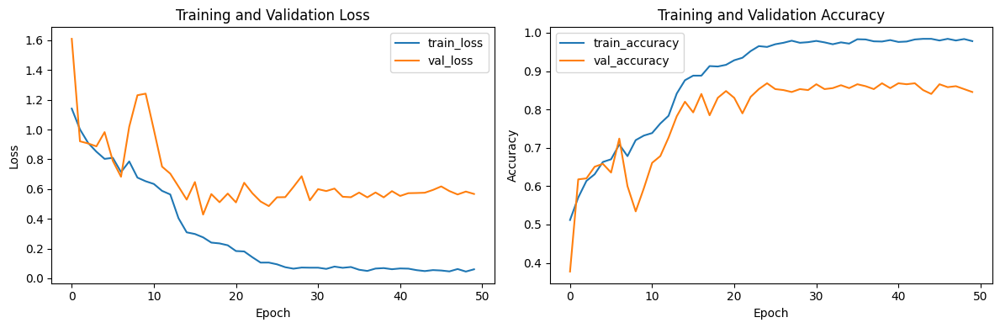

Validation loss: 0.4286
Validation accuracy: 0.8405
Test accuracy: 0.8561
              precision    recall  f1-score   support

       ASCUS       0.79      0.63      0.70        30
        HSIL       0.79      0.84      0.82       127
        LSIL       0.84      0.84      0.84        92
        NILM       0.99      1.00      0.99        92
         SCC       0.85      0.80      0.82        55

    accuracy                           0.86       396
   macro avg       0.85      0.82      0.83       396
weighted avg       0.86      0.86      0.86       396



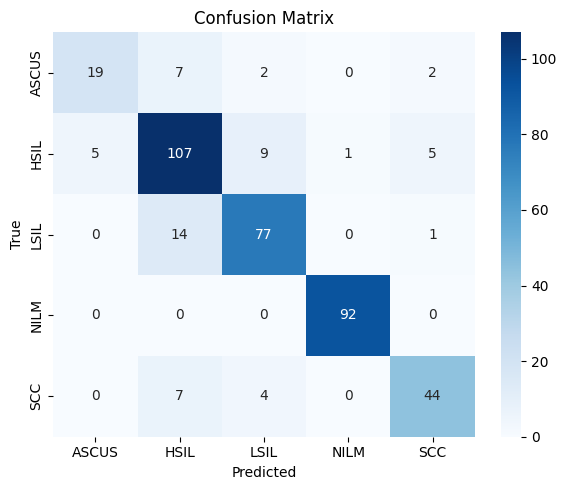

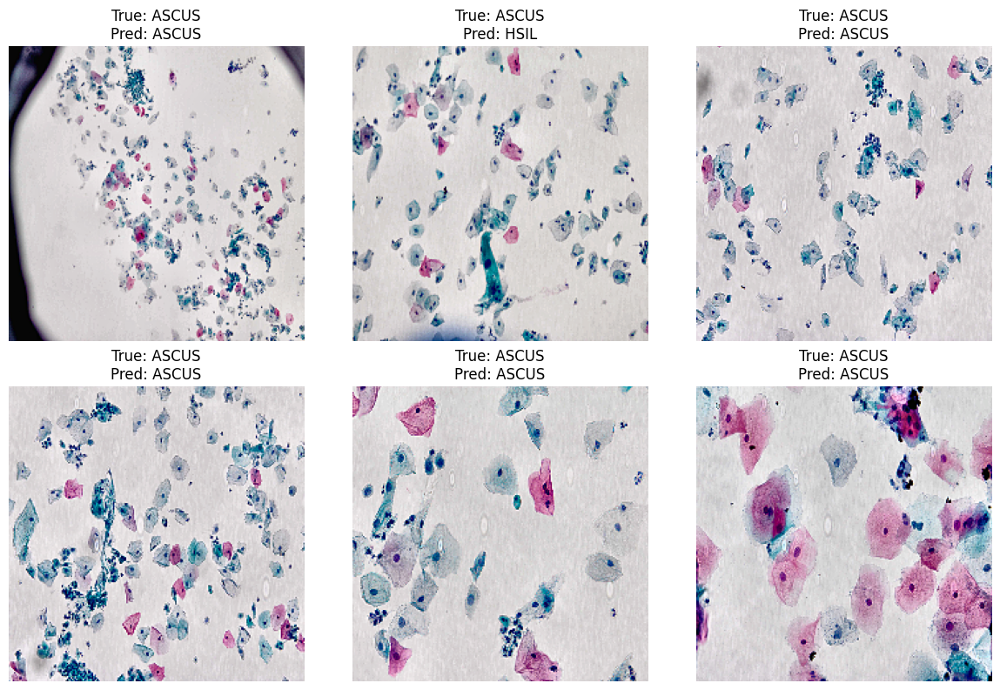


Per-class metrics:
ASCUS: precision=0.792, recall=0.633, f1=0.704
HSIL: precision=0.793, recall=0.843, f1=0.817
LSIL: precision=0.837, recall=0.837, f1=0.837
NILM: precision=0.989, recall=1.000, f1=0.995
SCC: precision=0.846, recall=0.800, f1=0.822


In [2]:
import os
import math
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

os.makedirs("plots", exist_ok=True)


def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


class CervicalCytologyDataset(Dataset):
    def __init__(self, data_root="data", split="train"):
        self.data_root = Path(data_root)
        self.split = split
        self.class_names = sorted([p.name for p in (self.data_root / split).iterdir() if p.is_dir()])
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for class_name in self.class_names:
            class_dir = self.data_root / split / class_name
            for image_path in sorted(class_dir.glob("*")):
                if image_path.is_file():
                    self.samples.append((str(image_path), self.class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label = self.samples[idx]
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_LINEAR)
        image = apcem_preprocess(image)
        image = image.transpose(2, 0, 1)
        image = torch.from_numpy(image).float()
        label = torch.tensor(label, dtype=torch.long)
        return image, label


import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.proj = None
        if stride != 1 or in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        # Let incoming shape be [B, in_channels, H, W]
        residual = x # Shape: [B, in_channels, H, W]
        
        if self.proj is not None:
            residual = self.proj(x) # Shape: [B, out_channels, H // stride, W // stride]
            
        x = self.conv1(x)       # Shape: [B, out_channels, H // stride, W // stride]
        x = self.bn1(x)         # Shape: [B, out_channels, H // stride, W // stride]
        x = F.relu(x)           # Shape: [B, out_channels, H // stride, W // stride]
        
        x = self.conv2(x)       # Shape: [B, out_channels, H // stride, W // stride]
        x = self.bn2(x)         # Shape: [B, out_channels, H // stride, W // stride]
        
        x = x + residual        # Shape: [B, out_channels, H // stride, W // stride]
        return F.relu(x)        # Shape: [B, out_channels, H // stride, W // stride]


class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1, padding=0)

    def forward(self, x):
        # Let incoming shape be [B, C, H, W]
        b, c, h, w = x.shape    # Extraction: b=B, c=C, h=H, w=W
        residual = x            # Shape: [B, C, H, W]
        
        # permute changes shape to [B, H, W, C] -> reshape flattens spatial dims
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c) # Shape: [B, H * W, C]
        
        flat = self.norm(flat)  # Shape: [B, H * W, C]
        
        # Self-attention operation over sequence length (H * W)
        attn_out, _ = self.attn(flat, flat, flat) # Shape: [B, H * W, C]
        
        # Reshape to spatial grid [B, H, W, C] -> permute back to channel-first [B, C, H, W]
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2) # Shape: [B, C, H, W]
        
        out = residual + self.proj(attn_out) # Shape: [B, C, H, W]
        return F.relu(out)      # Shape: [B, C, H, W]


class ResidualAttentionCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.block1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)
        self.block2 = ResidualBlock(32, 64, stride=2)
        self.attn2 = AttentionBlock(64)
        self.pool2 = nn.MaxPool2d(2)
        self.block3 = ResidualBlock(64, 128, stride=2)
        self.attn3 = AttentionBlock(128)
        self.pool3 = nn.MaxPool2d(2)
        self.block4 = ResidualBlock(128, 256, stride=2)
        self.attn4 = AttentionBlock(256)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Sequential(nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.3))
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # Input image shape assumption: [B, 3, 224, 224]
        
        x = self.stem(x)        # Shape: [B, 32, 224, 224]
        
        x = self.block1(x)      # Shape: [B, 32, 224, 224] (stride=1, in=out)
        x = self.pool1(x)       # Shape: [B, 32, 112, 112] (downsampled by 2)
        
        x = self.block2(x)      # Shape: [B, 64, 56, 56] (stride=2 halves H & W)
        x = self.attn2(x)       # Shape: [B, 64, 56, 56] (channels & space preserved)
        x = self.pool2(x)       # Shape: [B, 64, 28, 28] (downsampled by 2)
        
        x = self.block3(x)      # Shape: [B, 128, 14, 14] (stride=2 halves H & W)
        x = self.attn3(x)       # Shape: [B, 128, 14, 14] (channels & space preserved)
        x = self.pool3(x)       # Shape: [B, 128, 7, 7] (downsampled by 2)
        
        x = self.block4(x)      # Shape: [B, 256, 4, 4] (stride=2 downsamples 7x7 to 4x4 via floor rounding)
        x = self.attn4(x)       # Shape: [B, 256, 4, 4] (channels & space preserved)
        
        # Global Average Pooling reduces spatial dimensions (H, W) to 1x1
        # flatten(1) collapses dimensions from index 1 onwards: [B, 256, 1, 1] -> [B, 256]
        x = self.gap(x).flatten(1) # Shape: [B, 256]
        
        x = self.fc1(x)         # Shape: [B, 256]
        return self.fc2(x)      # Shape: [B, num_classes]



train_ds = CervicalCytologyDataset(data_root="data", split="train")
val_ds = CervicalCytologyDataset(data_root="data", split="val")
test_ds = CervicalCytologyDataset(data_root="data", split="test")

class_names = train_ds.class_names
print("Classes:", class_names)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

model = ResidualAttentionCNN(num_classes=len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)

best_val_loss = float("inf")
best_state = None
train_history = {"loss": [], "accuracy": []}
val_history = {"loss": [], "accuracy": []}

for epoch in range(50):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total
    train_history["loss"].append(train_loss)
    train_history["accuracy"].append(train_acc)

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            val_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_history["loss"].append(val_loss)
    val_history["accuracy"].append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch {epoch + 1:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | train_acc={train_acc:.4f} | val_acc={val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "multiclass_residual_attention_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)

model.eval()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_history["loss"], label="train_loss")
axes[0].plot(val_history["loss"], label="val_loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(train_history["accuracy"], label="train_accuracy")
axes[1].plot(val_history["accuracy"], label="val_accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
fig.savefig("plots/training_history.png", dpi=200)
plt.show()

val_loss = 0.0
val_correct = 0
val_total = 0
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        val_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        val_correct += (preds == labels).sum().item()
        val_total += labels.size(0)

val_loss /= val_total
val_acc = val_correct / val_total
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

all_true = []
all_pred = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()
        labels = labels.numpy()
        all_true.extend(labels.tolist())
        all_pred.extend(preds.tolist())

acc = accuracy_score(all_true, all_pred)
print(f"Test accuracy: {acc:.4f}")

report = classification_report(
    all_true,
    all_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
print(classification_report(all_true, all_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("plots/confusion_matrix.png", dpi=200)
plt.show()

sample_images, sample_labels = next(iter(test_loader))
sample_images = sample_images.to(device)
with torch.no_grad():
    sample_logits = model(sample_images)
    sample_pred = sample_logits.argmax(dim=1).cpu().numpy()

sample_images = sample_images.cpu().permute(0, 2, 3, 1).numpy()
sample_images = np.clip(sample_images, 0, 1)
true_labels = [class_names[i] for i in sample_labels.numpy()]
pred_labels = [class_names[i] for i in sample_pred]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, img, true_label, pred_label in zip(axes.flat, sample_images, true_labels, pred_labels):
    ax.imshow(img)
    ax.set_title(f"True: {true_label}\nPred: {pred_label}")
    ax.axis("off")

plt.tight_layout()
fig.savefig("plots/sample_predictions.png", dpi=200)
plt.show()

print("\nPer-class metrics:")
for cls in class_names:
    metrics = report[cls]
    print(f"{cls}: precision={metrics['precision']:.3f}, recall={metrics['recall']:.3f}, f1={metrics['f1-score']:.3f}")


# Custom CNN

In [ ]:
import os
import glob
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Coordinate File Parser & Mask Generator
# ---------------------------------------------------------

def load_dat_coordinates(dat_path):
    coords = []
    if not os.path.exists(dat_path):
        return None
    with open(dat_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.replace(',', ' ').split()
            if len(parts) >= 2:
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    coords.append([x, y])
                except ValueError:
                    continue
    return np.array(coords, dtype=np.int32)

# FIX 1: Updated base path to point to your current Kaggle input dataset folder
raw_path = "/kaggle/input/datasets/fahmidaifty/sipakmed/SipakMed" 
output_base_dir = "data"
IMG_SIZE = (224, 224)

# FIX 2: Updated folder paths with correct parent names and corrected "Abnormal" spelling
classes = [
    "Normal/im_Superficial-Intermediate",
    "Normal/im_Parabasal",
    "Abnormal/im_Koilocytotic",
    "Abnormal/im_Dyskeratotic",
    "Abnormal/im_Metaplastic"
]

for split in ["train", "val", "test"]:
    os.makedirs(f"{output_base_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{output_base_dir}/{split}/masks_nuc", exist_ok=True)
    os.makedirs(f"{output_base_dir}/{split}/masks_cyt", exist_ok=True)

all_pairs = []

for cls in classes:
    cropped_dir = os.path.join(raw_path, cls, cls, "CROPPED")
    if not os.path.exists(cropped_dir):
        cropped_dir = os.path.join(raw_path, cls, "CROPPED")
        if not os.path.exists(cropped_dir):
            continue
            
    bmp_files = glob.glob(os.path.join(cropped_dir, "*.bmp"))
    
    for bmp_path in bmp_files:
        base_name = os.path.splitext(os.path.basename(bmp_path))[0]
        cyt_dat_path = os.path.join(cropped_dir, f"{base_name}_cyt.dat")
        nuc_dat_path = os.path.join(cropped_dir, f"{base_name}_nuc.dat")
        
        if os.path.exists(cyt_dat_path) and os.path.exists(nuc_dat_path):
            all_pairs.append({
                "bmp_path": bmp_path,
                "cyt_dat": cyt_dat_path,
                "nuc_dat": nuc_dat_path,
                "base_name": base_name,
                "class_name": cls
            })

print(f"Identified {len(all_pairs)} matching image/coordinate sets.")

train_pairs, temp_pairs = train_test_split(all_pairs, test_size=0.30, random_state=42)
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, random_state=42)

splits = {
    "train": train_pairs,
    "val": val_pairs,
    "test": test_pairs
}

for split_name, pairs in splits.items():
    print(f"Processing and resizing {split_name} split...")
    for pair in pairs:
        img = cv2.imread(pair["bmp_path"])
        if img is None:
            continue
        h, w = img.shape[:2]

        cyt_mask = np.zeros((h, w), dtype=np.uint8)
        nuc_mask = np.zeros((h, w), dtype=np.uint8)

        cyt_pts = load_dat_coordinates(pair["cyt_dat"])
        nuc_pts = load_dat_coordinates(pair["nuc_dat"])

        if cyt_pts is not None and len(cyt_pts) > 0:
            cv2.drawContours(cyt_mask, [cyt_pts], -1, 255, -1)
        if nuc_pts is not None and len(nuc_pts) > 0:
            cv2.drawContours(nuc_mask, [nuc_pts], -1, 255, -1)

        img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        cyt_resized = cv2.resize(cyt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
        nuc_resized = cv2.resize(nuc_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        # FIX 3: Replaced the slash "/" with an underscore "_" to avoid FileNotFoundError
        prefix = f"{pair['class_name']}_{pair['base_name']}".replace("/", "_")
        
        cv2.imwrite(f"{output_base_dir}/{split_name}/images/{prefix}.png", img_resized)
        cv2.imwrite(f"{output_base_dir}/{split_name}/masks_cyt/{prefix}_cyt.png", cyt_resized)
        cv2.imwrite(f"{output_base_dir}/{split_name}/masks_nuc/{prefix}_nuc.png", nuc_resized)

print("Segmentation dataset generation completed successfully.")

# ---------------------------------------------------------
# 2. tf.data Loader Configured for Segmentation
# ---------------------------------------------------------
TARGET_MASK_TYPE = "masks_nuc" 

def get_paired_paths(split_name, mask_folder=TARGET_MASK_TYPE):
    images = sorted(glob.glob(f"data/{split_name}/images/*.png"))
    masks = sorted(glob.glob(f"data/{split_name}/{mask_folder}/*.png"))
    return images, masks

train_imgs, train_masks = get_paired_paths("train")
val_imgs, val_masks = get_paired_paths("val")
test_imgs, test_masks = get_paired_paths("test")

def load_and_preprocess_pair(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return img, mask

BATCH_SIZE = 16
train_dataset = tf.data.Dataset.from_tensor_slices((train_imgs, train_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(100).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_imgs, val_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_imgs, test_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [ ]:
# PyTorch custom CNN segmentation model for ablation study
# Includes residual blocks, attention blocks, skip connections, IoU metric, and visualization helpers

import os
import glob
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

try:
    from tqdm import tqdm
except ImportError:
    import sys
    !{sys.executable} -m pip install -q tqdm
    from tqdm import tqdm


def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)


class SegmentationDataset(Dataset):
    def __init__(self, split="train", img_dir="data", mask_dir="masks_nuc"):
        self.image_paths = sorted(glob.glob(os.path.join(img_dir, split, "images", "*.png")))
        self.mask_dir = os.path.join(img_dir, split, mask_dir)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = os.path.join(self.mask_dir, f"{base_name}_nuc.png")

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if img is None or mask is None:
            raise FileNotFoundError(f"Missing pair: {img_path} / {mask_path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (224, 224), interpolation=cv2.INTER_NEAREST)

        img = img.astype(np.float32) / 255.0
        mask = (mask > 0.5).astype(np.float32)

        img = torch.from_numpy(img).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)
        return img, mask


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        residual = self.shortcut(x)
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        x = x + residual
        return F.relu(x)


class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(1, channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        x = self.norm(x).permute(0, 2, 3, 1).reshape(b, h * w, c)
        attn_out, _ = self.attn(x, x, x)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        x = residual + attn_out
        return F.relu(x)


class CustomSegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.res1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.enc1 = nn.Sequential(
            ResidualBlock(32, 64, stride=2),
            AttentionBlock(64, heads=4),
        )
        self.pool2 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            ResidualBlock(64, 128, stride=2),
            AttentionBlock(128, heads=8),
        )
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            ResidualBlock(128, 256, stride=2),
            AttentionBlock(256, heads=8),
        )

        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec1 = ResidualBlock(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ResidualBlock(128, 64)
        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec3 = ResidualBlock(64, 32)

        self.out = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, out_channels, 1),
        )

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.res1(s0)

        x1 = self.pool1(s1)
        x1 = self.enc1(x1)

        x2 = self.pool2(x1)
        x2 = self.enc2(x2)

        x3 = self.pool3(x2)
        x3 = self.bottleneck(x3)

        x = self.up1(x3)
        if x.shape[2:] != x2.shape[2:]:
            x = F.interpolate(x, size=x2.shape[2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, x2], dim=1)
        x = self.dec1(x)

        x = self.up2(x)
        if x.shape[2:] != x1.shape[2:]:
            x = F.interpolate(x, size=x1.shape[2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, x1], dim=1)
        x = self.dec2(x)

        x = self.up3(x)
        if x.shape[2:] != s1.shape[2:]:
            x = F.interpolate(x, size=s1.shape[2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, s1], dim=1)
        x = self.dec3(x)

        return torch.sigmoid(self.out(x))


def dice_loss(y_true, y_pred, eps=1e-6):
    y_true_f = y_true.view(-1)
    y_pred_f = y_pred.view(-1)
    intersection = (y_true_f * y_pred_f).sum()
    union = y_true_f.sum() + y_pred_f.sum()
    return 1.0 - (2.0 * intersection + eps) / (union + eps)


def bce_dice_loss(y_true, y_pred):
    bce = nn.BCELoss()(y_pred, y_true)
    return bce + dice_loss(y_true, y_pred)


def compute_segmentation_metrics(y_true, y_pred, threshold=0.5):
    y_true_bin = (y_true > 0.5).float().view(-1)
    y_pred_bin = (y_pred > threshold).float().view(-1)

    tp = (y_true_bin * y_pred_bin).sum().item()
    fp = ((1 - y_true_bin) * y_pred_bin).sum().item()
    fn = (y_true_bin * (1 - y_pred_bin)).sum().item()
    tn = ((1 - y_true_bin) * (1 - y_pred_bin)).sum().item()

    intersection = tp
    union = y_true_bin.sum().item() + y_pred_bin.sum().item() - tp
    iou = intersection / (union + 1e-6)
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-6)
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    specificity = tn / (tn + fp + 1e-6)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-6)
    f1 = 2 * precision * recall / (precision + recall + 1e-6)

    return {
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "accuracy": accuracy,
        "f1": f1,
    }


def save_visualizations(model, loader, save_dir="manuscript_figures", n_samples=4):
    os.makedirs(save_dir, exist_ok=True)
    model.eval()
    with torch.no_grad():
        for i, (images, masks) in enumerate(loader):
            images = images.float().to(device)
            masks = masks.float().to(device)
            preds = model(images)
            for j in range(min(n_samples, images.size(0))):
                img = images[j].cpu().permute(1, 2, 0).numpy()
                mask = masks[j, 0].cpu().numpy()
                pred = preds[j, 0].cpu().numpy()

                fig, axes = plt.subplots(1, 3, figsize=(12, 4))
                axes[0].imshow(img)
                axes[0].set_title("Input")
                axes[0].axis("off")

                axes[1].imshow(mask, cmap="gray")
                axes[1].set_title("Ground Truth")
                axes[1].axis("off")

                axes[2].imshow(pred, cmap="gray")
                axes[2].set_title("Prediction")
                axes[2].axis("off")

                plt.tight_layout()
                fig.savefig(os.path.join(save_dir, f"sample_{i+1}_{j+1}.png"), dpi=200)
                plt.close(fig)
            break


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_dataset = SegmentationDataset(split="train")
val_dataset = SegmentationDataset(split="val")

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)

model = CustomSegNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

best_val_loss = float("inf")
train_metrics_history = []
val_metrics_history = []

for epoch in range(20):
    model.train()
    train_loss = 0.0
    train_metrics = {"iou": 0.0, "dice": 0.0, "precision": 0.0, "recall": 0.0, "specificity": 0.0, "accuracy": 0.0, "f1": 0.0}

    loop = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}/20 [train]")
    for _, (images, masks) in loop:
        images = images.float().to(device)
        masks = masks.float().to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = bce_dice_loss(masks, outputs)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        metrics = compute_segmentation_metrics(masks, outputs)
        for key in train_metrics:
            train_metrics[key] += metrics[key]

    model.eval()
    val_loss = 0.0
    val_metrics = {"iou": 0.0, "dice": 0.0, "precision": 0.0, "recall": 0.0, "specificity": 0.0, "accuracy": 0.0, "f1": 0.0}

    with torch.no_grad():
        val_loop = tqdm(enumerate(val_loader), total=len(val_loader), desc=f"Epoch {epoch+1}/20 [val]")
        for _, (images, masks) in val_loop:
            images = images.float().to(device)
            masks = masks.float().to(device)
            outputs = model(images)
            val_loss += bce_dice_loss(masks, outputs).item()
            metrics = compute_segmentation_metrics(masks, outputs)
            for key in val_metrics:
                val_metrics[key] += metrics[key]

    train_loss /= max(1, len(train_loader))
    val_loss /= max(1, len(val_loader))
    for key in train_metrics:
        train_metrics[key] /= max(1, len(train_loader))
        val_metrics[key] /= max(1, len(val_loader))

    train_metrics_history.append(train_metrics)
    val_metrics_history.append(val_metrics)

    print(
        f"Epoch {epoch+1:02d} | "
        f"train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f} | "
        f"train_iou: {train_metrics['iou']:.4f} | val_iou: {val_metrics['iou']:.4f} | "
        f"train_dice: {train_metrics['dice']:.4f} | val_dice: {val_metrics['dice']:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "custom_segnet_best.pt")

save_visualizations(model, val_loader, save_dir="manuscript_figures", n_samples=4)

print("PyTorch custom CNN segmentation training complete.")
print("Saved visualization figures to manuscript_figures/")
print("Final validation metrics:")
for key, value in val_metrics.items():
    print(f"  {key}: {value:.4f}")


# YOLO

In [ ]:
!pip install --quiet ultralytics

In [ ]:
import os
import glob
import cv2
import yaml
import numpy as np
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# 1. Configuration & Directories
# ---------------------------------------------------------
raw_path = "/kaggle/input/datasets/fahmidaifty/sipakmed/SipakMed" 
output_base_dir = "/kaggle/working/yolo_dataset"
TARGET_TYPE = "nuc"  # Change to "cyt" for cytoplasm segmentation

classes = [
    "Normal/im_Superficial-Intermediate",
    "Normal/im_Parabasal",
    "Abnormal/im_Koilocytotic",
    "Abnormal/im_Dyskeratotic",
    "Abnormal/im_Metaplastic"
]


# Create YOLO-compliant directory structure
for split in ["train", "val", "test"]:
    os.makedirs(f"{output_base_dir}/images/{split}", exist_ok=True)
    os.makedirs(f"{output_base_dir}/labels/{split}", exist_ok=True)


# ---------------------------------------------------------
# 2. Polygon Normalization Function for YOLO
# ---------------------------------------------------------
def get_normalized_coordinates(dat_path, img_w, img_h, class_id=0):
    """
    Parses absolute coordinates from .dat file and normalizes them 
    between 0.0 and 1.0 for YOLO segmentation.
    """
    if not os.path.exists(dat_path):
        return None
    coords = []
    with open(dat_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.replace(',', ' ').split()
            if len(parts) >= 2:
                try:
                    # Normalize by image width and height
                    x = float(parts[0]) / img_w
                    y = float(parts[1]) / img_h
                    # Clamp to ensure coordinates stay inside boundaries [0, 1]
                    x = min(max(x, 0.0), 1.0)
                    y = min(max(y, 0.0), 1.0)
                    coords.append(f"{x:.6f} {y:.6f}")
                except ValueError:
                    continue
    if len(coords) < 3:  # A valid polygon needs at least 3 vertices
        return None
    return f"{class_id} " + " ".join(coords)

# ---------------------------------------------------------
# 3. Pair Matching and Train/Val/Test Splitting
# ---------------------------------------------------------
all_pairs = []

for cls in classes:
    cropped_dir = os.path.join(raw_path, cls, cls, "CROPPED")
    if not os.path.exists(cropped_dir):
        cropped_dir = os.path.join(raw_path, cls, "CROPPED")
        if not os.path.exists(cropped_dir):
            continue
            
    bmp_files = glob.glob(os.path.join(cropped_dir, "*.bmp"))
    
    for bmp_path in bmp_files:
        base_name = os.path.splitext(os.path.basename(bmp_path))[0]
        dat_path = os.path.join(cropped_dir, f"{base_name}_{TARGET_TYPE}.dat")
        
        if os.path.exists(dat_path):
            all_pairs.append({
                "bmp_path": bmp_path,
                "dat_path": dat_path,
                "base_name": base_name,
                "class_name": cls
            })

print(f"Matched {len(all_pairs)} image/coordinate pairs.")

train_pairs, temp_pairs = train_test_split(all_pairs, test_size=0.30, random_state=42)
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, random_state=42)

splits = {
    "train": train_pairs,
    "val": val_pairs,
    "test": test_pairs
}

# ---------------------------------------------------------
# 4. Generate YOLO Dataset on Disk
# ---------------------------------------------------------
for split_name, pairs in splits.items():
    print(f"Processing and saving {split_name} split...")
    for pair in pairs:
        img = cv2.imread(pair["bmp_path"])
        if img is None:
            continue
        h, w = img.shape[:2]

        # Extract normalized YOLO coordinates
        yolo_label = get_normalized_coordinates(pair["dat_path"], w, h, class_id=0)
        
        if yolo_label is not None:
            prefix = f"{pair['class_name']}_{pair['base_name']}"

            img_out_dir = os.path.dirname(f"{output_base_dir}/images/{split_name}/{prefix}.jpg")
            label_out_dir = os.path.dirname(f"{output_base_dir}/labels/{split_name}/{prefix}.txt")
            
            os.makedirs(img_out_dir, exist_ok=True)
            os.makedirs(label_out_dir, exist_ok=True)
            
            # Save image as standard JPG
            img_out_path = f"{output_base_dir}/images/{split_name}/{prefix}.jpg"
            cv2.imwrite(img_out_path, img)

            # Save label in TXT file matching image filename
            label_out_path = f"{output_base_dir}/labels/{split_name}/{prefix}.txt"
            with open(label_out_path, 'w') as lf:
                lf.write(yolo_label + "\n")

# Write YOLO dataset configuration YAML file
data_yaml = {
    'path': output_base_dir,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {
        0: 'nucleus' if TARGET_TYPE == 'nuc' else 'cytoplasm'
    }
}

with open(f"{output_base_dir}/data.yaml", 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print("YOLO dataset structure and data.yaml successfully generated.")

In [ ]:
# Custom CNN segmentation model for ablation study
# Includes residual blocks, self-attention, and multi-head attention

import tensorflow as tf
from tensorflow.keras import layers, models


def residual_block(x, filters, strides=1, use_projection=False):
    shortcut = x
    if use_projection:
        shortcut = layers.Conv2D(filters, 1, strides=strides, padding="same")(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Conv2D(filters, 3, strides=strides, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)
    return x


def mha_block(x, heads=4):
    channels = x.shape[-1]
    head_dim = max(1, channels // heads)

    flat = layers.Reshape((-1, channels))(x)
    attn_output = layers.MultiHeadAttention(num_heads=heads, key_dim=head_dim)(flat, flat)
    attn_output = layers.Reshape((x.shape[1], x.shape[2], channels))(attn_output)

    x = layers.Add()([x, attn_output])
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)


def build_custom_cnn_segmentation(input_shape=(224, 224, 3)):
    inp = layers.Input(shape=input_shape)

    # Encoder
    x1 = layers.Conv2D(32, 3, padding="same")(inp)
    x1 = layers.BatchNormalization()(x1)
    x1 = layers.ReLU()(x1)
    x1 = residual_block(x1, 32)
    skip1 = x1

    x2 = layers.MaxPooling2D(2)(x1)
    x2 = residual_block(x2, 64, use_projection=True)
    x2 = mha_block(x2, heads=4)
    skip2 = x2

    x3 = layers.MaxPooling2D(2)(x2)
    x3 = residual_block(x3, 128, use_projection=True)
    x3 = mha_block(x3, heads=8)
    skip3 = x3

    x4 = layers.MaxPooling2D(2)(x3)
    x4 = residual_block(x4, 256, use_projection=True)
    x4 = mha_block(x4, heads=8)

    # Decoder
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(x4)
    x = layers.Concatenate()([u3, skip3])
    x = residual_block(x, 128, use_projection=True)

    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([u2, skip2])
    x = residual_block(x, 64, use_projection=True)

    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([u1, skip1])
    x = residual_block(x, 32, use_projection=True)

    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    out = layers.Conv2D(1, 1, activation="sigmoid")(x)
    return models.Model(inp, out)


# Losses and metrics

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    bce = tf.reduce_mean(bce)
    return bce + dice_loss(y_true, y_pred)


def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred > 0.5, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


custom_cnn_model = build_custom_cnn_segmentation()
custom_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=bce_dice_loss,
    metrics=["accuracy", iou_coef, dice_coef],
)

custom_cnn_model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
]

history = custom_cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=callbacks,
)

print("Custom CNN segmentation training complete.")

In [ ]:
from ultralytics import YOLO

# 1. Initialize YOLOv11 Nano Segmentation model
model = YOLO('yolo11n.pt')

# 2. Train the model
# YOLO manages learning rate decay, augmentations, and metrics internally
results = model.train(
    data=f"{output_base_dir}/data.yaml",
    epochs=50,
    imgsz=224,
    batch=16,
    project="cervical_segmentation",
    name="yolov11_segmentation_run"
)

# 3. Validate performance on the test set
val_results = model.val(split="test")

In [ ]:
import matplotlib.pyplot as plt

# Retrieve some test image paths
test_images = glob.glob(f"{output_base_dir}/images/test/Abnormal/*.jpg")

# Run inference on the first 3 test images
results = model(test_images[:3])

# Visualize and plot predictions
for i, r in enumerate(results):
    # Plot predicted masks and bounding boxes
    im_bgr = r.plot()  # Returns numpy array with visual overlays
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(6, 6))
    plt.imshow(im_rgb)
    plt.axis('off')
    plt.title(f"Prediction {i+1}")
    plt.show()

In [ ]:
import matplotlib.image as mpimg
img = mpimg.imread('/kaggle/working/runs/detect/cervical_segmentation/yolov11_segmentation_run-4/confusion_matrix.png')
plt.figure(figsize=(8, 8))
plt.imshow(img)
# Hide axes tick marks (optional)
plt.axis('off')

# Display the window
plt.show()

# U_NET

In [ ]:
import os
import glob
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Coordinate File Parser & Mask Generator
# ---------------------------------------------------------

def load_dat_coordinates(dat_path):
    coords = []
    if not os.path.exists(dat_path):
        return None
    with open(dat_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.replace(',', ' ').split()
            if len(parts) >= 2:
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    coords.append([x, y])
                except ValueError:
                    continue
    return np.array(coords, dtype=np.int32)

raw_path = "/kaggle/input/datasets/marinaeplissiti/sipakmed" 
output_base_dir = "data"
IMG_SIZE = (224, 224)

classes = [
    "im_Superficial-Intermediate",
    "im_Parabasal",
    "im_Koilocytotic",
    "im_Dyskeratotic",
    "im_Metaplastic"
]

for split in ["train", "val", "test"]:
    os.makedirs(f"{output_base_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{output_base_dir}/{split}/masks_nuc", exist_ok=True)
    os.makedirs(f"{output_base_dir}/{split}/masks_cyt", exist_ok=True)

all_pairs = []

for cls in classes:
    cropped_dir = os.path.join(raw_path, cls, cls, "CROPPED")
    if not os.path.exists(cropped_dir):
        cropped_dir = os.path.join(raw_path, cls, "CROPPED")
        if not os.path.exists(cropped_dir):
            continue
            
    bmp_files = glob.glob(os.path.join(cropped_dir, "*.bmp"))
    
    for bmp_path in bmp_files:
        base_name = os.path.splitext(os.path.basename(bmp_path))[0]
        cyt_dat_path = os.path.join(cropped_dir, f"{base_name}_cyt.dat")
        nuc_dat_path = os.path.join(cropped_dir, f"{base_name}_nuc.dat")
        
        if os.path.exists(cyt_dat_path) and os.path.exists(nuc_dat_path):
            all_pairs.append({
                "bmp_path": bmp_path,
                "cyt_dat": cyt_dat_path,
                "nuc_dat": nuc_dat_path,
                "base_name": base_name,
                "class_name": cls
            })

print(f"Identified {len(all_pairs)} matching image/coordinate sets.")

train_pairs, temp_pairs = train_test_split(all_pairs, test_size=0.30, random_state=42)
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, random_state=42)

splits = {
    "train": train_pairs,
    "val": val_pairs,
    "test": test_pairs
}

for split_name, pairs in splits.items():
    print(f"Processing and resizing {split_name} split...")
    for pair in pairs:
        img = cv2.imread(pair["bmp_path"])
        if img is None:
            continue
        h, w = img.shape[:2]

        cyt_mask = np.zeros((h, w), dtype=np.uint8)
        nuc_mask = np.zeros((h, w), dtype=np.uint8)

        cyt_pts = load_dat_coordinates(pair["cyt_dat"])
        nuc_pts = load_dat_coordinates(pair["nuc_dat"])

        if cyt_pts is not None and len(cyt_pts) > 0:
            cv2.drawContours(cyt_mask, [cyt_pts], -1, 255, -1)
        if nuc_pts is not None and len(nuc_pts) > 0:
            cv2.drawContours(nuc_mask, [nuc_pts], -1, 255, -1)

        img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
        cyt_resized = cv2.resize(cyt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
        nuc_resized = cv2.resize(nuc_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        prefix = f"{pair['class_name']}_{pair['base_name']}"
        cv2.imwrite(f"{output_base_dir}/{split_name}/images/{prefix}.png", img_resized)
        cv2.imwrite(f"{output_base_dir}/{split_name}/masks_cyt/{prefix}_cyt.png", cyt_resized)
        cv2.imwrite(f"{output_base_dir}/{split_name}/masks_nuc/{prefix}_nuc.png", nuc_resized)

print("Segmentation dataset generation completed successfully.")

# ---------------------------------------------------------
# 2. tf.data Loader Configured for Segmentation
# ---------------------------------------------------------
TARGET_MASK_TYPE = "masks_nuc" 

def get_paired_paths(split_name, mask_folder=TARGET_MASK_TYPE):
    images = sorted(glob.glob(f"data/{split_name}/images/*.png"))
    masks = sorted(glob.glob(f"data/{split_name}/{mask_folder}/*.png"))
    return images, masks

train_imgs, train_masks = get_paired_paths("train")
val_imgs, val_masks = get_paired_paths("val")
test_imgs, test_masks = get_paired_paths("test")

def load_and_preprocess_pair(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return img, mask

BATCH_SIZE = 16
train_dataset = tf.data.Dataset.from_tensor_slices((train_imgs, train_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(100).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_imgs, val_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_imgs, test_masks))\
    .map(load_and_preprocess_pair, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# ---------------------------------------------------------
# 3. Model Architecture (CervicalNet_UNet with Regularization)
# ---------------------------------------------------------
def grouped_conv(x, filters, groups=4):
    c = x.shape[-1]
    group_size = c // groups
    outputs = []

    for i in range(groups):
        xi = layers.Lambda(lambda z: z[..., i*group_size:(i+1)*group_size])(x)
        xi = layers.Conv2D(filters//groups, 3, padding="same")(xi)
        outputs.append(xi)

    return layers.Concatenate()(outputs)

def conv_block(x, filters):
    """
    Standard convolutional block incorporating Grouped Convolutions
    and Batch Normalization for feature stabilization.
    """
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = grouped_conv(x, filters)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def CervicalNet_UNet(input_shape=(224, 224, 3)):
    inp = layers.Input(shape=input_shape)

    # --- ENCODER (Downsampling Path) ---
    # Block 1 (Resolution: 224x224 -> 112x112)
    x1 = conv_block(inp, 32)
    p1 = layers.AveragePooling2D(pool_size=2)(x1) 

    # Block 2 (Resolution: 112x112 -> 56x56)
    x2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D(pool_size=2)(x2) 

    # Block 3 (Bottleneck: 56x56)
    x3 = conv_block(p2, 128)

    # --- DECODER (Upsampling Path with True Skip Connections) ---
    # Up Block 2 (Resolution: 56x56 -> 112x112)
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(x3)
    c2 = layers.Concatenate()([u2, x2])  # Properly aligned skip connection
    x4 = conv_block(c2, 64)

    # Up Block 1 (Resolution: 112x112 -> 224x224)
    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(x4)
    c1 = layers.Concatenate()([u1, x1])  # Properly aligned skip connection
    x5 = conv_block(c1, 32)
    
    # Sigmoid activation output layer
    out = layers.Conv2D(1, 1, activation="sigmoid")(x5)

    return models.Model(inp, out)

model = CervicalNet_UNet()
model.summary()


# ---------------------------------------------------------
# 4. Corrected Metrics, Losses & Compilation
# ---------------------------------------------------------
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    bce = tf.reduce_mean(bce)
    return bce + dice_loss(y_true, y_pred)

def iou_coef(y_true, y_pred, smooth=1e-6):
    """
    Thresholded IoU metric for stable, accurate validation tracking
    on continuous predictions.
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred > 0.5, [-1]), tf.float32) # Applied threshold
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), 
    loss=bce_dice_loss, 
    metrics=["accuracy", iou_coef, dice_coef]
)


# ---------------------------------------------------------
# 5. Training Callbacks & Execution
# ---------------------------------------------------------
# Prevent overfitting and dynamically adjust learning rate
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
]

epochs = 50
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs,
    callbacks=callbacks
)

# Test evaluation

In [ ]:
!pip install --quiet protobuf==3.20.*
!pip install --quiet tensorflow==2.15

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (224,224)
batch = 32

datagen = ImageDataGenerator(rescale=1/255.)

train_gen = datagen.flow_from_directory(
    "data/train",
    target_size=img_size,
    batch_size=batch,
    class_mode="categorical"
)

val_gen = datagen.flow_from_directory(
    "data/val",
    target_size=img_size,
    batch_size=batch,
    class_mode="categorical"
)

test_gen = datagen.flow_from_directory(
    "data/test",
    target_size=img_size,
    batch_size=batch,
    class_mode="categorical",
    shuffle=False
)


In [ ]:
import os
import glob
import shutil
from sklearn.model_selection import train_test_split

raw_path = "../input/sipakmed"     # your Kaggle path

classes = [
    "im_Superficial-Intermediate",
    "im_Parabasal",
    "im_Koilocytotic",
    "im_Dyskeratotic",
    "im_Metaplastic"
]

# create new directory structure
for split in ["train", "val", "test"]:
    os.makedirs(f"data/{split}", exist_ok=True)
    for cls in classes:
        os.makedirs(f"data/{split}/{cls}", exist_ok=True)

# process each class
for cls in classes:
    img_path = os.path.join(raw_path, cls, cls, "CROPPED", "*.bmp")
    imgs = glob.glob(img_path)

    labels = [cls] * len(imgs)

    # 70% train, 15% val, 15% test
    train_imgs, temp_imgs, _, temp_labels = train_test_split(
        imgs, labels, test_size=0.30, stratify=labels, random_state=42)

    val_imgs, test_imgs, _, _ = train_test_split(
        temp_imgs, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42)

    # copy files
    for f in train_imgs:
        shutil.copy(f, f"data/train/{cls}/")
    for f in val_imgs:
        shutil.copy(f, f"data/val/{cls}/")
    for f in test_imgs:
        shutil.copy(f, f"data/test/{cls}/")

print("Dataset split completed!")


In [ ]:
def grouped_conv(x, filters, groups=4):
    c = x.shape[-1]
    group_size = c // groups
    outputs = []

    for i in range(groups):
        xi = layers.Lambda(lambda z: z[..., i*group_size:(i+1)*group_size])(x)
        xi = layers.Conv2D(filters//groups, 3, padding="same")(xi)
        outputs.append(xi)

    return layers.Concatenate()(outputs)

def CervicalNet():
    inp = layers.Input(shape=(224,224,3))

    # BLOCK 1
    x = layers.Conv2D(32, 3, padding="same")(inp)
    x = layers.ReLU()(x)
    x = layers.AveragePooling2D(pool_size=2)(x)     # FIXED
    x = grouped_conv(x, 32)

    # BLOCK 2
    x = layers.ReLU()(x)
    x = layers.AveragePooling2D(pool_size=2)(x)     # FIXED
    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.ReLU()(x)

    # BLOCK 3
    x = grouped_conv(x, 64)
    x = layers.ReLU()(x)
    x = grouped_conv(x, 128)
    x = layers.ReLU()(x)

    # Final Layers
    x = layers.GlobalAveragePooling2D()(x)
    feat = layers.Dense(1024)(x)
    out = layers.Dense(5, activation="softmax")(feat)

    return models.Model(inp, out), models.Model(inp, feat)

# Build Models
cnet, cnet_feat = CervicalNet()
cnet.summary()


In [ ]:
cnet.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnet.fit(train_gen, validation_data=val_gen, epochs=80)


In [ ]:
!wget -O shufflenetv2-1x.h5 https://github.com/Callidior/keras-applications/releases/download/shufflenet_v2/shufflenetv2-1x.h5

In [ ]:
mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)
mobilenet.trainable = False

print("MobileNetV2 loaded.")

In [ ]:
def extract_features(gen, model):
    feats, labels = [], []
    for x, y in gen:
        feats.append(model(x).numpy())
        labels.append(np.argmax(y, axis=1))
        if len(feats)*gen.batch_size >= gen.samples:
            break
    return np.concatenate(feats), np.concatenate(labels)

m_train, y_train = extract_features(train_gen, mobilenet)
m_test, y_test   = extract_features(test_gen, mobilenet)

c_train, _ = extract_features(train_gen, cnet_feat)
c_test, _  = extract_features(test_gen,  cnet_feat)


In [ ]:
pca_m = PCA(n_components=544)
m_train_p = pca_m.fit_transform(m_train)
m_test_p  = pca_m.transform(m_test)

pca_c = PCA(n_components=544)
c_train_p = pca_c.fit_transform(c_train)
c_test_p  = pca_c.transform(c_test)


In [ ]:
train_fused = np.concatenate([m_train_p, c_train_p], axis=1)
test_fused  = np.concatenate([m_test_p,  c_test_p],  axis=1)

train_fused.shape, test_fused.shape


In [ ]:
models_dict = {
    "SVM": SVC(kernel="rbf", probability=True),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "RF": RandomForestClassifier(n_estimators=200),
    "NB": GaussianNB(),
    "ANN": MLPClassifier(hidden_layer_sizes=(256,128), max_iter=300)
}

results = {}

for name, clf in models_dict.items():
    clf.fit(train_fused, y_train)
    pred = clf.predict(test_fused)
    
    acc = accuracy_score(y_test, pred)
    rep = classification_report(y_test, pred, output_dict=True)
    
    results[name] = {
        "Accuracy": acc,
        "Precision": rep["weighted avg"]["precision"],
        "Recall": rep["weighted avg"]["recall"],
        "F1 Score": rep["weighted avg"]["f1-score"]
    }

df = pd.DataFrame(results).T
df


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Class names (in the same order as train_gen.class_indices)
class_labels = list(train_gen.class_indices.keys())

def plot_cm(cm, title):
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

for name, clf in models_dict.items():
    preds = clf.predict(test_fused)
    cm = confusion_matrix(y_test, preds)
    plot_cm(cm, f"Confusion Matrix — {name}")
